### Finding Log.txt Files

In [2]:
# Check what your local __init__.py actually does
with open(os.path.join("..", "unet", "__init__.py")) as f:
    print(f.read())

from .unet_model import UNet


In [6]:
import sys, os

# Nuke cached modules
for key in list(sys.modules.keys()):
    if "unet" in key.lower():
        del sys.modules[key]

# Insert the PARENT of your local unet/ folder (i.e., Prune_U-Net/)
# NOT the unet/ folder itself
local_parent_path = os.path.abspath("..")   # goes from analysis/ → Prune_U-Net/
sys.path.insert(0, local_parent_path)

# Verify
import unet
print("Using unet from:", unet.__file__)
# Should now show: .../Prune_U-Net/unet/__init__.py

from unet.unet_model import UNet
import inspect
print(inspect.signature(UNet.__init__))
# Should show: (self, n_channels, n_classes, ...)




Using unet from: /home/jovyan/pruning-datavol-1/Prune_U-Net/unet/__init__.py
(self, n_channels, n_classes, f_channels)


In [7]:
# Cell 0 — Imports
from __future__ import annotations

import os
import re
import json
from pathlib import Path
from typing import Any, Dict, Optional, Tuple, List

import pandas as pd


In [8]:
# Cell 1 — Configure paths (notebook sits next to save/ and save_grouped/)
ROOT = Path(".").resolve()
SAVE_DIRS = [ROOT / "../save_mri/decoder"]

for d in SAVE_DIRS:
    print("Exists:", d, "->", d.exists())


Exists: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder -> True


In [9]:
# Cell 2 — Find all log.txt files
def find_logs(save_dirs: List[Path]) -> List[Path]:
    logs: List[Path] = []
    for base in save_dirs:
        if not base.exists():
            continue
        logs.extend(base.rglob("log.txt"))
    # deterministic order
    logs = sorted(set(logs), key=lambda p: str(p).lower())
    return logs

log_paths = find_logs(SAVE_DIRS)
print(f"Found {len(log_paths)} log.txt files")
log_paths[:20]


Found 18 log.txt files


[PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-01/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-02/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-03/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-04/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-05/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-06/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-07/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-08/log.txt'),
 PosixPath('/home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../save_mri/decoder/test/decoder-09/log.txt'),
 

### Helpers

In [10]:
import os
import re
import json
from pathlib import Path
import pandas as pd
import numpy as np

# ----------------------------
# Small parsing utilities
# ----------------------------

PARTS = ["inc", "down1", "down2", "down3", "down4", "up1", "up2", "up3", "up4", "outc", "other"]

def _to_int_commas(x: str):
    if x is None:
        return np.nan
    x = x.strip().replace(",", "")
    return int(x) if x.isdigit() or (x and x[0] == "-" and x[1:].isdigit()) else np.nan

def _to_float(x: str):
    try:
        return float(x)
    except Exception:
        return np.nan

def _parse_g_token(tok: str):
    # "1.906G" -> 1.906
    if tok is None:
        return np.nan
    tok = tok.strip()
    m = re.match(r"^([+-]?\d+(?:\.\d+)?)G$", tok)
    return float(m.group(1)) if m else np.nan

def _parse_pct_token(tok: str):
    # "98.26%" or "nan%"
    if tok is None:
        return np.nan
    tok = tok.strip().replace("%", "")
    if tok.lower() == "nan":
        return np.nan
    return _to_float(tok)

def _extract_args_block(text: str):
    """
    Extracts the JSON dict after 'Args: {' ... '}'.
    Uses brace counting so it works even if the args span many lines.
    """
    anchor = "Args:"
    i = text.find(anchor)
    if i < 0:
        return {}
    j = text.find("{", i)
    if j < 0:
        return {}
    depth = 0
    end = None
    for k in range(j, len(text)):
        if text[k] == "{":
            depth += 1
        elif text[k] == "}":
            depth -= 1
            if depth == 0:
                end = k + 1
                break
    if end is None:
        return {}
    blob = text[j:end]
    try:
        return json.loads(blob)
    except Exception:
        # If the JSON has trailing commas or minor issues, fall back to a safer eval-like parsing
        return {}

def _infer_experiment_type(args: dict):
    # global
    if "prune_channels" in args and args["prune_channels"] is not None:
        return "global"
    # grouped flavors
    pe = args.get("prune_encoder", 0) or 0
    pb = args.get("prune_bottleneck", 0) or 0
    pd = args.get("prune_decoder", 0) or 0
    pdown = args.get("prune_down_total", -1)
    pdown = pdown if pdown is not None else -1

    # pooled down mode
    if pdown is not None and pdown >= 0:
        if pd > 0 and pdown > 0:
            return "pooled_down+decoder"
        if pdown > 0:
            return "pooled_down"
    # separate budgets
    nz = sum(int(x > 0) for x in [pe, pb, pd])
    if nz == 1 and pe > 0:
        return "enc_only"
    if nz == 1 and pb > 0:
        return "bottleneck_only"
    if nz == 1 and pd > 0:
        return "dec_only"
    if nz >= 2:
        return "mixed_grouped"
    return "grouped_unknown"

def _infer_requested_budget(args: dict):
    # Prefer explicit effective total if present (your grouped logs have it)
    if "prune_total_effective" in args and args["prune_total_effective"] is not None:
        return int(args["prune_total_effective"])
    if "prune_channels" in args and args["prune_channels"] is not None:
        return int(args["prune_channels"])

    # Grouped fallback
    pe = int(args.get("prune_encoder", 0) or 0)
    pb = int(args.get("prune_bottleneck", 0) or 0)
    pd = int(args.get("prune_decoder", 0) or 0)
    pdown = args.get("prune_down_total", -1)
    pdown = int(pdown) if pdown is not None else -1
    if pdown >= 0:
        return pdown + pd
    return pe + pb + pd

def _extract_removed_channels_reported(text: str):
    # Old format: removed 1100 channels
    m = re.search(r"Pruning complete:\s*removed\s+(\d+)\s+channels", text)
    if m:
        return int(m.group(1))

    # New format: requested removal=208
    m = re.search(r"Pruning complete:\s*requested removal=(\d+)", text)
    if m:
        return int(m.group(1))

    # Group pruning variant
    m = re.search(r"Group pruning complete:\s*removed\s+(\d+)\s+channels", text)
    if m:
        return int(m.group(1))

    return np.nan


def _extract_final_summary_metrics(text: str):
    """
    Parse FINAL SUMMARY table rows:
      Dice | baseline | pruned | delta | ratio%
      Params | baseline | pruned | delta... | ratio%
      Size (MB) | ...
      FLOPs | 1.906G | 1.826G | ... | 95.79%
    Returns a dict with both baseline and pruned numeric values.
    """
    out = {}

    # Dice
    m = re.search(r"^\[.*?\]\s*Dice\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*([+-]?[0-9.]+)\s*\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["dice_baseline"] = _to_float(m.group(1))
        out["dice_pruned"] = _to_float(m.group(2))
        out["dice_delta"] = _to_float(m.group(3))
        out["dice_ratio_pct"] = _to_float(m.group(4))

    # Params
    m = re.search(r"^\[.*?\]\s*Params\s*\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|\s*.*?\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["params_baseline"] = _to_int_commas(m.group(1))
        out["params_pruned"] = _to_int_commas(m.group(2))
        out["params_keep_pct"] = _to_float(m.group(3))
        out["params_ratio"] = out["params_pruned"] / out["params_baseline"] if out["params_baseline"] else np.nan
        out["params_reduction_pct"] = 100.0 * (1 - out["params_ratio"]) if pd.notna(out["params_ratio"]) else np.nan

    # Size
    m = re.search(r"^\[.*?\]\s*Size\s*\(MB\)\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*.*?\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["size_mb_baseline"] = _to_float(m.group(1))
        out["size_mb_pruned"] = _to_float(m.group(2))
        out["size_keep_pct"] = _to_float(m.group(3))
        out["size_ratio"] = out["size_mb_pruned"] / out["size_mb_baseline"] if out["size_mb_baseline"] else np.nan
        out["size_reduction_pct"] = 100.0 * (1 - out["size_ratio"]) if pd.notna(out["size_ratio"]) else np.nan

    # FLOPs
    m = re.search(r"^\[.*?\]\s*FLOPs\s*\|\s*([0-9.]+G)\s*\|\s*([0-9.]+G)\s*\|\s*.*?\|\s*([0-9.]+)%\s*$",
                  text, flags=re.MULTILINE)
    if m:
        out["flops_g_baseline"] = _parse_g_token(m.group(1))
        out["flops_g_pruned"] = _parse_g_token(m.group(2))
        out["flops_keep_pct"] = _to_float(m.group(3))
        out["flops_ratio"] = out["flops_g_pruned"] / out["flops_g_baseline"] if out["flops_g_baseline"] else np.nan
        out["flops_reduction_pct"] = 100.0 * (1 - out["flops_ratio"]) if pd.notna(out["flops_ratio"]) else np.nan

    return out

def _extract_per_part_table(text: str, which: str):
    """
    which in {"flops", "params"}.
    Parses PER-PART table into fixed columns:
      part_{which}_baseline, part_{which}_pruned, part_{which}_delta, part_{which}_ratio_pct

    FLOPs tokens are like 0.247G, 0.000G; Params are 38,848 etc.
    """
    assert which in {"flops", "params"}
    section_title = "PER-PART FLOPs" if which == "flops" else "PER-PART Params"

    # Grab only the part of the log starting at that section; stop at the next big separator of a different section.
    i = text.find(section_title)
    if i < 0:
        return {}

    # Take a reasonably bounded window after the section
    chunk = text[i:i+8000]

    out = {}
    for part in PARTS:
        # Typical row:
        # [..] down1 | 0.177G | 0.171G | -0.006G | 96.88%
        # [..] down1 | 221,696 | 203,616 | -18080 | 91.84%
        if which == "flops":
            row_re = rf"^\[.*?\]\s*{re.escape(part)}\s*\|\s*([0-9.]+G)\s*\|\s*([0-9.]+G)\s*\|\s*([+-]?[0-9.]+G)\s*\|\s*([0-9.]+%|nan%)\s*$"
            m = re.search(row_re, chunk, flags=re.MULTILINE)
            if m:
                out[f"{part}_flops_g_baseline"] = _parse_g_token(m.group(1))
                out[f"{part}_flops_g_pruned"]   = _parse_g_token(m.group(2))
                out[f"{part}_flops_g_delta"]    = _parse_g_token(m.group(3))
                out[f"{part}_flops_ratio_pct"]  = _parse_pct_token(m.group(4))
        else:
            row_re = rf"^\[.*?\]\s*{re.escape(part)}\s*\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|\s*([+-]?\d+)\s*\|\s*([0-9.]+%|nan%)\s*$"
            m = re.search(row_re, chunk, flags=re.MULTILINE)
            if m:
                out[f"{part}_params_baseline"]  = _to_int_commas(m.group(1))
                out[f"{part}_params_pruned"]    = _to_int_commas(m.group(2))
                out[f"{part}_params_delta"]     = _to_int_commas(m.group(3))
                out[f"{part}_params_ratio_pct"] = _parse_pct_token(m.group(4))

    return out

def _extract_aggregated_groups(text: str):
    i = text.find("AGGREGATED GROUPS")
    if i < 0:
        return {}

    chunk = text[i:i+4000]

    groups = ["ENCODER", "BOTTLENECK", "DECODER"]
    out = {}

    for g in groups:
        # Match table row
        # ENCODER (...) | 4687296 | 4687296 | 0.00% | 0.022 | 0.022 | 0.00%
        pattern = (
            rf"{g}.*?\|\s*([\d,]+)\s*\|\s*([\d,]+)\s*\|\s*([0-9.]+)%"
            rf"\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)\s*\|\s*([0-9.]+)%"
        )

        m = re.search(pattern, chunk)
        if m:
            gname = g.lower()

            out[f"{gname}_params_baseline"] = _to_int_commas(m.group(1))
            out[f"{gname}_params_pruned"] = _to_int_commas(m.group(2))
            out[f"{gname}_params_reduce_pct"] = _to_float(m.group(3))

            out[f"{gname}_flops_g_baseline"] = _to_float(m.group(4))
            out[f"{gname}_flops_g_pruned"] = _to_float(m.group(5))
            out[f"{gname}_flops_reduce_pct"] = _to_float(m.group(6))

    return out


def parse_single_log(log_path: str):
    text = Path(log_path).read_text(encoding="utf-8", errors="ignore")

    args = _extract_args_block(text)
    # Flatten nested "budget" dict if present
    if "budget" in args and isinstance(args["budget"], dict):
        for k, v in args["budget"].items():
            if k not in args:
                args[k] = v
    
    exp_type = _infer_experiment_type(args)
    requested_budget = _infer_requested_budget(args)
    removed_reported = _extract_removed_channels_reported(text)

    # This is now the authoritative source for baseline/pruned metrics
    summary = _extract_final_summary_metrics(text)

    per_part_flops = _extract_per_part_table(text, which="flops")
    per_part_params = _extract_per_part_table(text, which="params")
    aggs = _extract_aggregated_groups(text)

    row = {
        "log_path": str(log_path),
        "experiment_type": exp_type,
        "requested_budget_channels": requested_budget,
        "removed_channels_reported": removed_reported,
    }

    # Model name
    if exp_type == "global":
        row["model_name"] = f"global_b{requested_budget}"
    elif exp_type == "enc_only":
        row["model_name"] = f"enc_only_e{int(args.get('prune_encoder', 0) or 0)}"
    elif exp_type == "bottleneck_only":
        row["model_name"] = f"bottleneck_only_b{int(args.get('prune_bottleneck', 0) or 0)}"
    elif exp_type == "dec_only":
        row["model_name"] = f"dec_only_d{int(args.get('prune_decoder', 0) or 0)}"
    elif exp_type == "pooled_down+decoder":
        row["model_name"] = f"pooled_down{int(args.get('prune_down_total', 0) or 0)}_dec{int(args.get('prune_decoder', 0) or 0)}"
    elif exp_type == "mixed_grouped":
        row["model_name"] = f"mixed_e{int(args.get('prune_encoder',0) or 0)}_b{int(args.get('prune_bottleneck',0) or 0)}_d{int(args.get('prune_decoder',0) or 0)}"
    else:
        row["model_name"] = f"{exp_type}_b{requested_budget}"

    # Add args (prefixed)
    for k, v in args.items():
        row[f"arg_{k}"] = v

    # Add summary metrics (baseline + pruned)
    row.update(summary)

    # Add per-part and aggregated
    row.update(per_part_flops)
    row.update(per_part_params)
    row.update(aggs)

    return row


### Execution

In [11]:
# Cell — Scan logs and build baseline + runs tables
rows = []
bad = []
for lp in log_paths:
    try:
        rows.append(parse_single_log(lp))
    except Exception as e:
        bad.append((lp, repr(e)))

if bad:
    print("Failed logs:", len(bad))
    print("First 5 failures:")
    for lp, err in bad[:5]:
        print("  -", lp, err)

df_all = pd.DataFrame(rows)

# ----------------------------
# Build a SINGLE baseline row
# ----------------------------
# Baseline should be identical across runs; we derive it from the FINAL SUMMARY baseline columns
# and the per-part baseline columns from any log that has them.

# pick candidates that have dice_baseline and params_baseline
cand = df_all[df_all["dice_baseline"].notna() & df_all["params_baseline"].notna()].copy()
if len(cand) == 0:
    raise RuntimeError("No logs contained FINAL SUMMARY baseline metrics (dice_baseline/params_baseline).")

# Use median to be robust; then verify max deviation
baseline = {}
for col in ["dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"]:
    if col in cand.columns:
        baseline[col] = cand[col].median()

# Per-part baseline columns: take from the first log that contains each column
baseline_source_row = cand.iloc[0].to_dict()
for part in PARTS:
    # FLOPs baseline per-part
    c = f"{part}_flops_g_baseline"
    if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
        baseline[c] = baseline_source_row[c]
    # Params baseline per-part
    c = f"{part}_params_baseline"
    if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
        baseline[c] = baseline_source_row[c]

# Aggregated groups baseline (params + flops_abs)
for g in ["encoder", "bottleneck", "decoder"]:
    for c in [f"{g}_params_baseline", f"{g}_flops_abs_baseline"]:
        if c in df_all.columns and pd.notna(baseline_source_row.get(c, np.nan)):
            baseline[c] = baseline_source_row[c]

df_baseline = pd.DataFrame([{
    "model_name": "BASELINE",
    "experiment_type": "baseline",
    "log_path": "",  # baseline is not a log; it is inferred from logs
    **baseline
}])

# ----------------------------
# Build df_runs: one row per pruned experiment (no baseline redundancy)
# ----------------------------
df_runs = df_all.copy()

# Ensure baseline metrics are filled (never NaN) using the baseline row values
for k, v in baseline.items():
    if k in df_runs.columns and df_runs[k].isna().any():
        df_runs[k] = df_runs[k].fillna(v)

# Now compute consistent deltas/ratios against the baseline row (even if the log didn't print % fields)
df_runs["dice_drop"] = df_runs["dice_baseline"] - df_runs["dice_pruned"]
df_runs["dice_keep"] = df_runs["dice_pruned"] / df_runs["dice_baseline"]

df_runs["params_ratio"] = df_runs["params_pruned"] / df_runs["params_baseline"]
df_runs["params_reduction_pct"] = 100 * (1 - df_runs["params_ratio"])

df_runs["size_ratio"] = df_runs["size_mb_pruned"] / df_runs["size_mb_baseline"]
df_runs["size_reduction_pct"] = 100 * (1 - df_runs["size_ratio"])

df_runs["flops_ratio"] = df_runs["flops_g_pruned"] / df_runs["flops_g_baseline"]
df_runs["flops_reduction_pct"] = 100 * (1 - df_runs["flops_ratio"])

# Per-part ratios/deltas re-derived (so you can rely on them, even if "nan%" printed)
for part in PARTS:
    # FLOPs per-part
    b = f"{part}_flops_g_baseline"
    p = f"{part}_flops_g_pruned"
    if b in df_runs.columns and p in df_runs.columns:
        df_runs[f"{part}_flops_g_delta_recalc"] = df_runs[p] - df_runs[b]
        df_runs[f"{part}_flops_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})
    # Params per-part
    b = f"{part}_params_baseline"
    p = f"{part}_params_pruned"
    if b in df_runs.columns and p in df_runs.columns:
        df_runs[f"{part}_params_delta_recalc"] = df_runs[p] - df_runs[b]
        df_runs[f"{part}_params_ratio_recalc"] = df_runs[p] / df_runs[b].replace({0: np.nan})

# Remove baseline columns from runs to reduce redundancy (keep only what’s needed)
# Keep baseline scalar columns if you prefer; otherwise you can drop them.
drop_baseline_cols = [c for c in df_runs.columns if c.endswith("_baseline") and c not in ["dice_baseline","params_baseline","size_mb_baseline","flops_g_baseline"]]
# The per-part baseline columns are the main redundancy:
drop_perpart_baseline = [c for c in df_runs.columns if c.endswith("_flops_g_baseline") or c.endswith("_params_baseline")]
# Aggregated baseline redundancy:
drop_agg_baseline = [c for c in df_runs.columns if c.endswith("_params_baseline") or c.endswith("_flops_abs_baseline")]

# Keep the 4 scalar baseline metrics because they are useful for sanity; if you want, drop them too.
keep_scalar_baseline = {"dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"}
drop_cols = sorted(set(drop_perpart_baseline + drop_agg_baseline) - keep_scalar_baseline)

df_runs = df_runs.drop(columns=[c for c in drop_cols if c in df_runs.columns])

# Add a baseline_id to join later if needed
df_runs["baseline_id"] = 0
df_baseline["baseline_id"] = 0

print("df_baseline shape:", df_baseline.shape)
print("df_runs shape:", df_runs.shape)

display(df_baseline)
display(df_runs.head(10))


df_baseline shape: (1, 33)
df_runs shape: (18, 179)


,model_name,experiment_type,log_path,dice_baseline,params_baseline,size_mb_baseline,flops_g_baseline,inc_flops_g_baseline,inc_params_baseline,down1_flops_g_baseline,...,up4_flops_g_baseline,up4_params_baseline,outc_flops_g_baseline,outc_params_baseline,other_flops_g_baseline,other_params_baseline,encoder_params_baseline,bottleneck_params_baseline,decoder_params_baseline,baseline_id
0,BASELINE,baseline,,0.880062,31037698.0,118.484,0.076,0.01,38848,0.007,...,0.028,143680,0.0,130,0.0,0,4687296,14159872,12190530,0


,log_path,experiment_type,requested_budget_channels,removed_channels_reported,model_name,arg_name,arg_save_dir,arg_device,arg_data_root,arg_scale,...,up4_params_ratio_recalc,outc_flops_g_delta_recalc,outc_flops_ratio_recalc,outc_params_delta_recalc,outc_params_ratio_recalc,other_flops_g_delta_recalc,other_flops_ratio_recalc,other_params_delta_recalc,other_params_ratio_recalc,baseline_id
0,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,200,208,dec_only_d200,decoder,save_mri/decoder/test/decoder-01,cuda,dataset_split,0.5,...,1.000000,0.0,NaN,0,1.000000,0.0,NaN,0,NaN,0
1,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,300,304,dec_only_d300,decoder,save_mri/decoder/test/decoder-02,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
2,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,400,400,dec_only_d400,decoder,save_mri/decoder/test/decoder-03,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
3,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,500,512,dec_only_d500,decoder,save_mri/decoder/test/decoder-04,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
4,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,600,608,dec_only_d600,decoder,save_mri/decoder/test/decoder-05,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
5,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,700,704,dec_only_d700,decoder,save_mri/decoder/test/decoder-06,cuda,dataset_split,0.5,...,0.907127,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
6,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,800,800,dec_only_d800,decoder,save_mri/decoder/test/decoder-07,cuda,dataset_split,0.5,...,0.702004,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
7,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,900,912,dec_only_d900,decoder,save_mri/decoder/test/decoder-08,cuda,dataset_split,0.5,...,0.702004,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
8,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,1000,1008,dec_only_d1000,decoder,save_mri/decoder/test/decoder-09,cuda,dataset_split,0.5,...,0.702004,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0
9,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,dec_only,1100,1104,dec_only_d1100,decoder,save_mri/decoder/test/decoder-10,cuda,dataset_split,0.5,...,0.673497,0.0,NaN,-32,0.753846,0.0,NaN,0,NaN,0


In [12]:
# Cell — Integrity check for df_baseline + df_runs

def _missing_report(d: pd.DataFrame, name: str, key_cols):
    miss = d[key_cols].isna().sum().sort_values(ascending=False)
    miss_pct = (miss / len(d) * 100).round(2) if len(d) else miss * 0
    out = pd.DataFrame({"na": miss, "na_%": miss_pct})
    print(f"\n{name} — rows={len(d)}, cols={d.shape[1]}")
    display(out[out["na"] > 0])

# 1) Baseline must have no NaNs in the core baseline metrics
baseline_required = ["dice_baseline", "params_baseline", "size_mb_baseline", "flops_g_baseline"]
_missing_report(df_baseline, "df_baseline", baseline_required)

# 2) Runs must have no NaNs in core run metrics
runs_required = [
    "model_name", "experiment_type", "requested_budget_channels", "removed_channels_reported", "log_path",
    "dice_pruned", "params_pruned", "size_mb_pruned", "flops_g_pruned",
    "dice_drop", "params_reduction_pct", "size_reduction_pct", "flops_reduction_pct",
]
_missing_report(df_runs, "df_runs", [c for c in runs_required if c in df_runs.columns])

# 3) Sanity: metrics ranges
issues = []
def flag(mask, msg):
    n = int(mask.sum())
    if n > 0:
        issues.append((msg, n, df_runs.loc[mask, ["model_name","experiment_type","log_path"]].head(10)))

if "dice_pruned" in df_runs.columns:
    flag(df_runs["dice_pruned"].notna() & ((df_runs["dice_pruned"] < 0) | (df_runs["dice_pruned"] > 1)),
         "dice_pruned outside [0,1]")
if "flops_g_pruned" in df_runs.columns and "flops_g_baseline" in df_runs.columns:
    flag(df_runs["flops_g_pruned"] > df_runs["flops_g_baseline"] * 1.001,
         "flops_g_pruned > flops_g_baseline (unexpected)")
if "params_pruned" in df_runs.columns and "params_baseline" in df_runs.columns:
    flag(df_runs["params_pruned"] > df_runs["params_baseline"],
         "params_pruned > params_baseline (unexpected)")

print("\nSanity issues:")
if not issues:
    print("None")
else:
    for msg, n, sample in issues:
        print(f"- {msg}: {n} rows")
        display(sample)



df_baseline — rows=1, cols=33


,na,na_%



df_runs — rows=18, cols=179


,na,na_%



Sanity issues:
None


## Loading the corresponding models

In [13]:
# Cell 5 — Resolve run_dir + finetuned ckpt + pruned_channels.txt (same approach as notebook)

def run_dir_from_log_path(log_path: str) -> Path:
    p = Path(str(log_path))
    if p.is_dir():
        return p
    if p.name.lower() == "log.txt":
        return p.parent
    return p.parent

def find_finetuned_ckpt(run_dir: Path) -> Path:
    for name in ["Finetuned.pth", "finetuned.pth"]:
        p = run_dir / name
        if p.exists():
            return p
    cands = [p for p in run_dir.glob("*.pth") if "finetuned" in p.name.lower()]
    if cands:
        # notebook logic: pick the largest (usually the real finetuned weights)
        cands = sorted(cands, key=lambda p: p.stat().st_size, reverse=True)
        return cands[0]
    raise FileNotFoundError(f"No Finetuned checkpoint found in {run_dir}")

def find_channels_txt(run_dir: Path) -> Path:
    p = run_dir / "pruned_channels.txt"
    if not p.exists():
        raise FileNotFoundError(f"Missing pruned_channels.txt in {run_dir} (cannot build pruned architecture)")
    return p

df_models = df_runs.copy()
df_models["run_dir"] = df_models["log_path"].apply(lambda p: str(run_dir_from_log_path(p).resolve()))

ckpts, chans, ok = [], [], []
for _, r in df_models.iterrows():
    try:
        rd = Path(r["run_dir"])
        ckpt = find_finetuned_ckpt(rd)
        ch = find_channels_txt(rd)
        ckpts.append(str(ckpt.resolve()))
        chans.append(str(ch.resolve()))
        ok.append(True)
    except Exception:
        ckpts.append("")
        chans.append("")
        ok.append(False)

df_models["finetuned_ckpt"] = ckpts
df_models["channels_txt"] = chans
df_models["has_finetuned_files"] = ok

print("Runnable finetuned runs:", int(df_models["has_finetuned_files"].sum()), "/", len(df_models))
display(df_models.loc[df_models["has_finetuned_files"], ["experiment_type", "model_name", "requested_budget_channels", "finetuned_ckpt", "channels_txt"]].head(20))


Runnable finetuned runs: 18 / 18


,experiment_type,model_name,requested_budget_channels,finetuned_ckpt,channels_txt
0,dec_only,dec_only_d200,200,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
1,dec_only,dec_only_d300,300,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
2,dec_only,dec_only_d400,400,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
3,dec_only,dec_only_d500,500,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
4,dec_only,dec_only_d600,600,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
5,dec_only,dec_only_d700,700,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
6,dec_only,dec_only_d800,800,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
7,dec_only,dec_only_d900,900,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
8,dec_only,dec_only_d1000,1000,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
9,dec_only,dec_only_d1100,1100,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...


In [14]:
import sys, os

# Nuke cached modules
for key in list(sys.modules.keys()):
    if "unet" in key.lower():
        del sys.modules[key]

# Insert the PARENT of your local unet/ folder (i.e., Prune_U-Net/)
# NOT the unet/ folder itself
local_parent_path = os.path.abspath("..")   # goes from analysis/ → Prune_U-Net/
sys.path.insert(0, local_parent_path)

# Verify
import unet
print("Using unet from:", unet.__file__)
# Should now show: .../Prune_U-Net/unet/__init__.py

from unet.unet_model import UNet
import inspect
print(inspect.signature(UNet.__init__))
# Should show: (self, n_channels, n_classes, ...)




Using unet from: /home/jovyan/pruning-datavol-1/Prune_U-Net/unet/__init__.py
(self, n_channels, n_classes, f_channels)


In [15]:
# Cell 6 — Import UNet + build_model_for_checkpoint (same as notebook’s Prune_U-Net import)

import torch
import sys

PRUNE_UNET_DIR = (Path(".").resolve() / "Prune_U-Net")
if str(PRUNE_UNET_DIR) not in sys.path:
    sys.path.insert(0, str(PRUNE_UNET_DIR))

N_CHANNELS = 3
N_CLASSES  = 2

def build_model_for_checkpoint(channel_txt_path: str) -> torch.nn.Module:
    return UNet(n_channels=N_CHANNELS, n_classes=N_CLASSES, f_channels=str(channel_txt_path))


In [16]:
# Cell 7 — Load finetuned models correctly (channels txt always applied; weights_only when available)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = False  # keep same default behavior unless you explicitly benchmark FP16

def safe_load_state_dict(path: str):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        return torch.load(path, map_location="cpu")

def load_finetuned_model(ckpt_path: str, channels_txt: str) -> torch.nn.Module:
    m = build_model_for_checkpoint(channels_txt).to(DEVICE)

    sd = safe_load_state_dict(ckpt_path)
    sd = safe_load_state_dict(ckpt_path)

    # strip DDP "module."
    if isinstance(sd, dict) and any(isinstance(k, str) and k.startswith("module.") for k in sd.keys()):
        sd = {k.replace("module.", "", 1): v for k, v in sd.items()}

    m.load_state_dict(sd, strict=True)
    m.eval()

    if DEVICE == "cuda":
        m = m.to(memory_format=torch.channels_last)
    if USE_FP16 and DEVICE == "cuda":
        m = m.half()

    return m


In [17]:
# Cell 8 — Optional: load all finetuned models into a dict (for your next experiments)

models_by_name = {}
fail = []

runnable = df_models[df_models["has_finetuned_files"]].copy()

for _, r in runnable.iterrows():
    try:
        name = r["model_name"]
        models_by_name[name] = load_finetuned_model(r["finetuned_ckpt"], r["channels_txt"])
    except Exception as e:
        fail.append((r.get("model_name", ""), r.get("finetuned_ckpt", ""), repr(e)))

print("Loaded models:", len(models_by_name))
if fail:
    print("Load failures:", len(fail))
    print("First 5:")
    for x in fail[:5]:
        print("  -", x)

# Quick sanity on one model
if models_by_name:
    k0 = next(iter(models_by_name.keys()))
    m0 = models_by_name[k0]
    print("Example model:", k0, "| #params:", sum(p.numel() for p in m0.parameters()))


/opt/conda/envs/unet/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Loaded models: 18
Example model: dec_only_d200 | #params: 29522274


# Studying the Drop

## at {300, 400, 500} channels

In [18]:
# Cell 9 — Focus set: decoder-only @ budgets 300/400/500 (pick good@300, catastrophic@400, good@500)

import numpy as np
import pandas as pd

TARGET_BUDGETS = [300,400, 500]

src = df_models.copy()

# keep only decoder-only runs at those budgets
df_dec = src[
    (src["experiment_type"] == "dec_only") &
    (src["requested_budget_channels"].isin(TARGET_BUDGETS))
].copy()

if df_dec.empty:
    raise RuntimeError("No decoder-only runs found for budgets 300/400/500. Check experiment_type and requested_budget_channels.")

# selection policy:
#  - 300: highest dice (a 'good' one)
#  - 400: lowest dice (the catastrophic one)
#  - 500: highest dice (a 'good' one)
picked = []
for b in TARGET_BUDGETS:
    d = df_dec[df_dec["requested_budget_channels"] == b].copy()
    d = d.dropna(subset=["dice_pruned"])
    if d.empty:
        raise RuntimeError(f"No rows with dice_pruned for decoder-only budget={b}.")
    if b == 400:
        row = d.sort_values("dice_pruned", ascending=True).iloc[0]
    else:
        row = d.sort_values("dice_pruned", ascending=False).iloc[0]
    picked.append(row)

df_focus = pd.DataFrame(picked).reset_index(drop=True)

# convenience
df_focus["budget"] = df_focus["requested_budget_channels"]

cols_show = [
    "budget", "model_name", "dice_pruned",
    "params_pruned", "params_reduction_pct",
    "flops_g_pruned", "flops_reduction_pct",
    "log_path", "run_dir", "finetuned_ckpt", "channels_txt"
]
display(df_focus[cols_show])


,budget,model_name,dice_pruned,params_pruned,params_reduction_pct,flops_g_pruned,flops_reduction_pct,log_path,run_dir,finetuned_ckpt,channels_txt
0,300,dec_only_d300,0.860830,28951938,6.720086,0.075,1.315789,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
1,400,dec_only_d400,0.854474,28109250,9.435133,0.074,2.631579,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...
2,500,dec_only_d500,0.863740,27372258,11.809639,0.074,2.631579,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...,/home/jovyan/pruning-datavol-1/Prune_U-Net/sav...


In [19]:
# Cell 10 — Baseline accessors (per-part baseline values + overall)

from typing import Dict, List, Tuple, Optional
import math

def _get_baseline_row() -> pd.Series:
    if df_baseline is None or len(df_baseline) == 0:
        raise RuntimeError("df_baseline is missing.")
    return df_baseline.iloc[0]

BASE = _get_baseline_row()

# Parts expected from your logs
PARTS_CORE = ["inc", "down1", "down2", "down3", "down4", "up1", "up2", "up3", "up4", "outc"]
PARTS_EXTRA = ["other"]  # include only if present
PARTS_ALL = PARTS_CORE + [p for p in PARTS_EXTRA if f"{p}_params_pruned" in df_focus.columns]

# Grouping (matches how you usually talk about encoder/bottleneck/decoder)
GROUPS = {
    "encoder":    ["inc", "down1", "down2", "down3"],
    "bottleneck": ["down4"],
    "decoder":    ["up1", "up2", "up3", "up4", "outc"],
}
if "other" in PARTS_ALL:
    GROUPS["other"] = ["other"]

def _baseline_part_vals(kind: str, parts: List[str]) -> np.ndarray:
    """
    kind:
      - "params" -> expects {part}_params_baseline in df_baseline
      - "flops"  -> expects {part}_flops_g_baseline in df_baseline
    """
    vals = []
    for p in parts:
        col = f"{p}_params_baseline" if kind == "params" else f"{p}_flops_g_baseline"
        if col not in df_baseline.columns or pd.isna(BASE.get(col, np.nan)):
            raise RuntimeError(f"Missing baseline column in df_baseline: {col}")
        vals.append(float(BASE[col]))
    return np.array(vals, dtype=float)

def _pruned_part_vals(row: pd.Series, kind: str, parts: List[str]) -> np.ndarray:
    vals = []
    for p in parts:
        col = f"{p}_params_pruned" if kind == "params" else f"{p}_flops_g_pruned"
        if col not in row.index or pd.isna(row.get(col, np.nan)):
            raise RuntimeError(f"Missing pruned column in df_focus row: {col}")
        vals.append(float(row[col]))
    return np.array(vals, dtype=float)

def _sum_by_groups(vals_by_part: Dict[str, float]) -> Dict[str, float]:
    out = {}
    for g, ps in GROUPS.items():
        out[g] = float(sum(vals_by_part.get(p, 0.0) for p in ps))
    return out

print("Baseline totals:",
      "params=", int(BASE["params_baseline"]),
      "| flops_g=", float(BASE.get("flops_g_baseline", np.nan)))


Baseline totals: params= 31037698 | flops_g= 0.076


In [20]:
# Cell 11 — Plot helpers: "baseline behind, pruned in front" (absolute) + share annotations

import matplotlib.pyplot as plt

def _plot_baseline_vs_pruned_abs(
    labels: List[str],
    base_vals: np.ndarray,
    pruned_vals: np.ndarray,
    title: str,
    ylabel: str,
    subtitle: Optional[str] = None,
    share_of_total: bool = True,
):
    x = np.arange(len(labels), dtype=float)

    plt.figure(figsize=(12, 4.2))
    # baseline behind
    plt.bar(x, base_vals, width=0.80, alpha=0.25)
    # pruned in front
    plt.bar(x, pruned_vals, width=0.55, alpha=0.95)

    plt.xticks(x, labels, rotation=0)
    plt.ylabel(ylabel)
    plt.title(title if subtitle is None else f"{title}\n{subtitle}")
    plt.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

    if share_of_total:
        tot = float(np.sum(pruned_vals)) if np.sum(pruned_vals) > 0 else 0.0
        for i, v in enumerate(pruned_vals):
            if tot > 0:
                pct = 100.0 * float(v) / tot
                plt.text(i, v, f"{pct:.1f}%", ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()


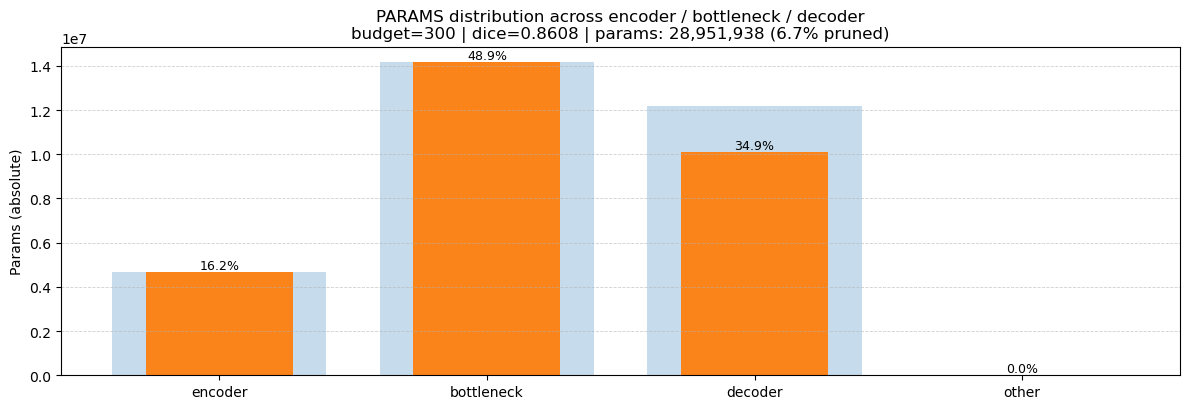

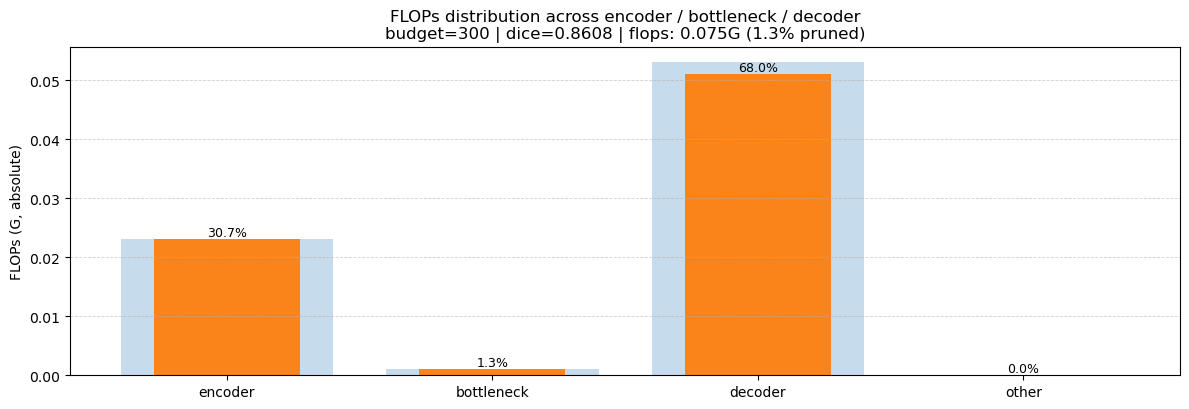

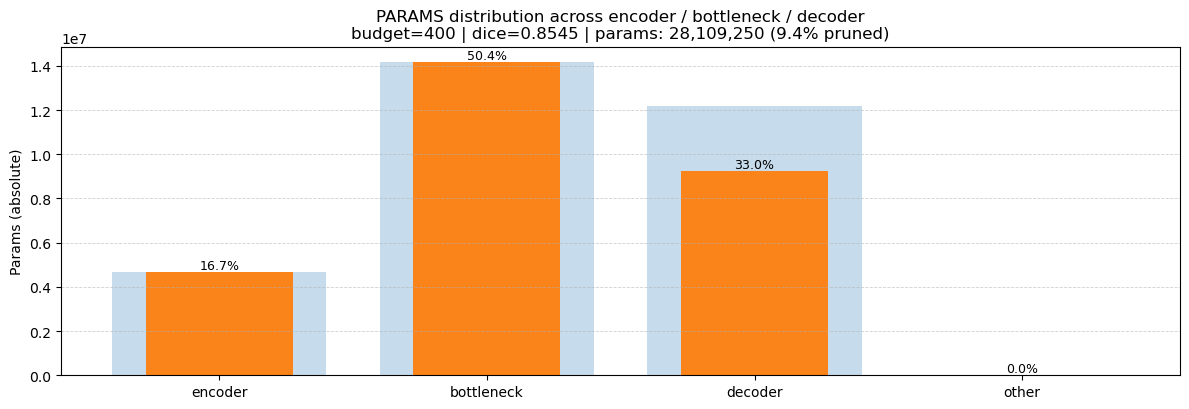

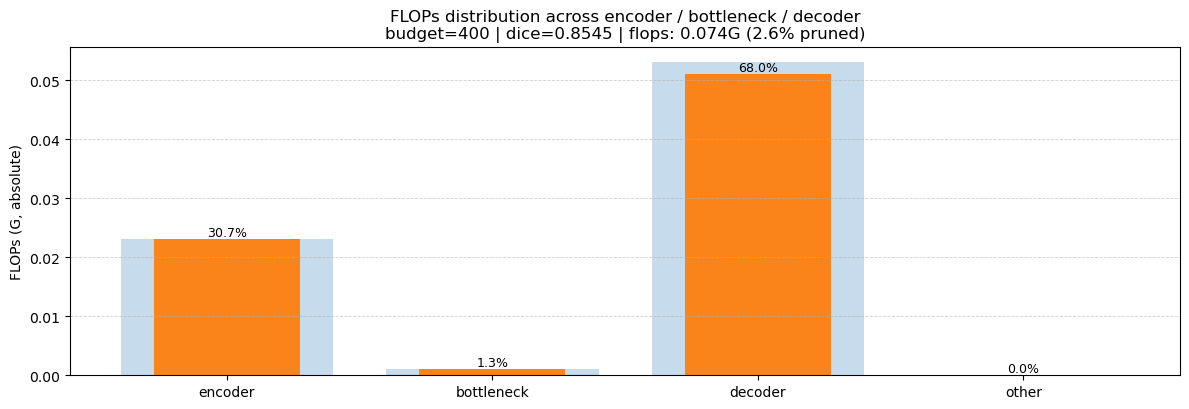

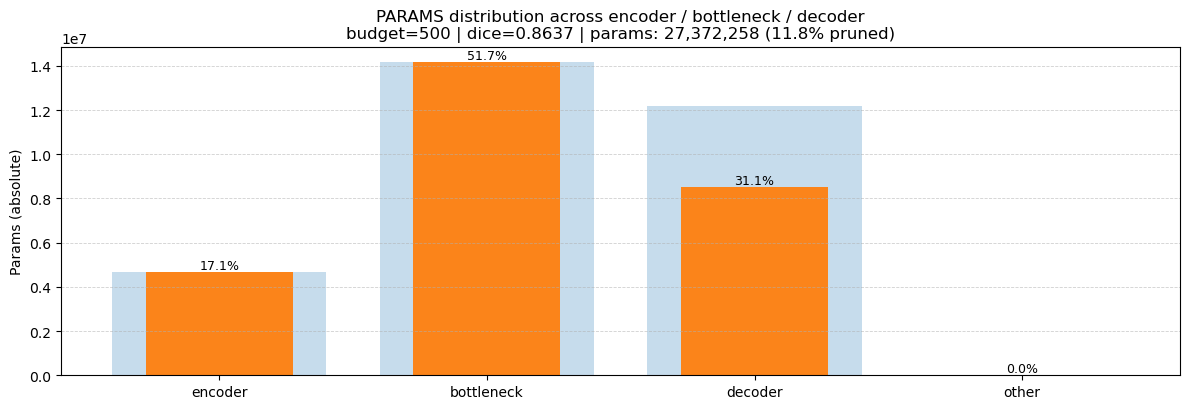

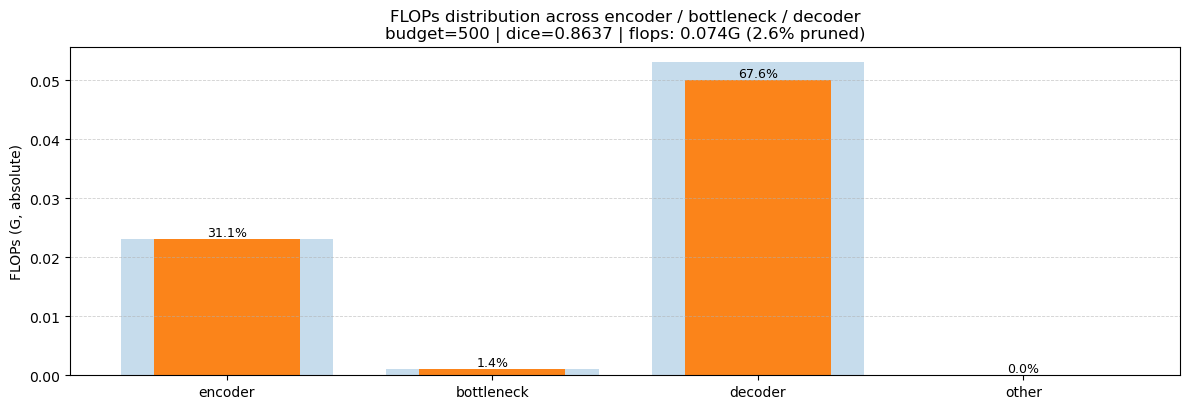

In [21]:
# Cell 12 — Decoder-only deep dive plots (GROUP level): params + flops
# (3 budgets -> 6 figures)

def plot_groups_for_row(row: pd.Series):
    # build group totals from per-part values (params)
    base_p_parts = {p: float(BASE[f"{p}_params_baseline"]) for p in PARTS_ALL if f"{p}_params_baseline" in df_baseline.columns}
    prun_p_parts = {p: float(row[f"{p}_params_pruned"]) for p in PARTS_ALL}

    base_p_groups = _sum_by_groups(base_p_parts)
    prun_p_groups = _sum_by_groups(prun_p_parts)

    labels = list(base_p_groups.keys())
    base_vals = np.array([base_p_groups[k] for k in labels], dtype=float)
    prun_vals = np.array([prun_p_groups[k] for k in labels], dtype=float)

    subtitle = (
        f"budget={int(row['budget'])} | dice={row['dice_pruned']:.4f} | "
        f"params: {int(row['params_pruned']):,} ({row['params_reduction_pct']:.1f}% pruned)"
    )

    _plot_baseline_vs_pruned_abs(
        labels=labels,
        base_vals=base_vals,
        pruned_vals=prun_vals,
        title="PARAMS distribution across encoder / bottleneck / decoder",
        ylabel="Params (absolute)",
        subtitle=subtitle,
        share_of_total=True,
    )

    # FLOPs groups (if per-part FLOPs exist)
    flops_cols = [f"{p}_flops_g_pruned" for p in PARTS_ALL]
    if all(c in row.index and pd.notna(row[c]) for c in flops_cols):
        base_f_parts = {p: float(BASE[f"{p}_flops_g_baseline"]) for p in PARTS_ALL if f"{p}_flops_g_baseline" in df_baseline.columns}
        prun_f_parts = {p: float(row[f"{p}_flops_g_pruned"]) for p in PARTS_ALL}
        base_f_groups = _sum_by_groups(base_f_parts)
        prun_f_groups = _sum_by_groups(prun_f_parts)

        labels = list(base_f_groups.keys())
        base_vals = np.array([base_f_groups[k] for k in labels], dtype=float)
        prun_vals = np.array([prun_f_groups[k] for k in labels], dtype=float)

        subtitle = (
            f"budget={int(row['budget'])} | dice={row['dice_pruned']:.4f} | "
            f"flops: {row['flops_g_pruned']:.3f}G ({row['flops_reduction_pct']:.1f}% pruned)"
        )

        _plot_baseline_vs_pruned_abs(
            labels=labels,
            base_vals=base_vals,
            pruned_vals=prun_vals,
            title="FLOPs distribution across encoder / bottleneck / decoder",
            ylabel="FLOPs (G, absolute)",
            subtitle=subtitle,
            share_of_total=True,
        )
    else:
        print(f"[SKIP FLOPs GROUPS] Missing per-part FLOPs columns for budget={int(row['budget'])}")

for _, r in df_focus.sort_values("budget").iterrows():
    plot_groups_for_row(r)


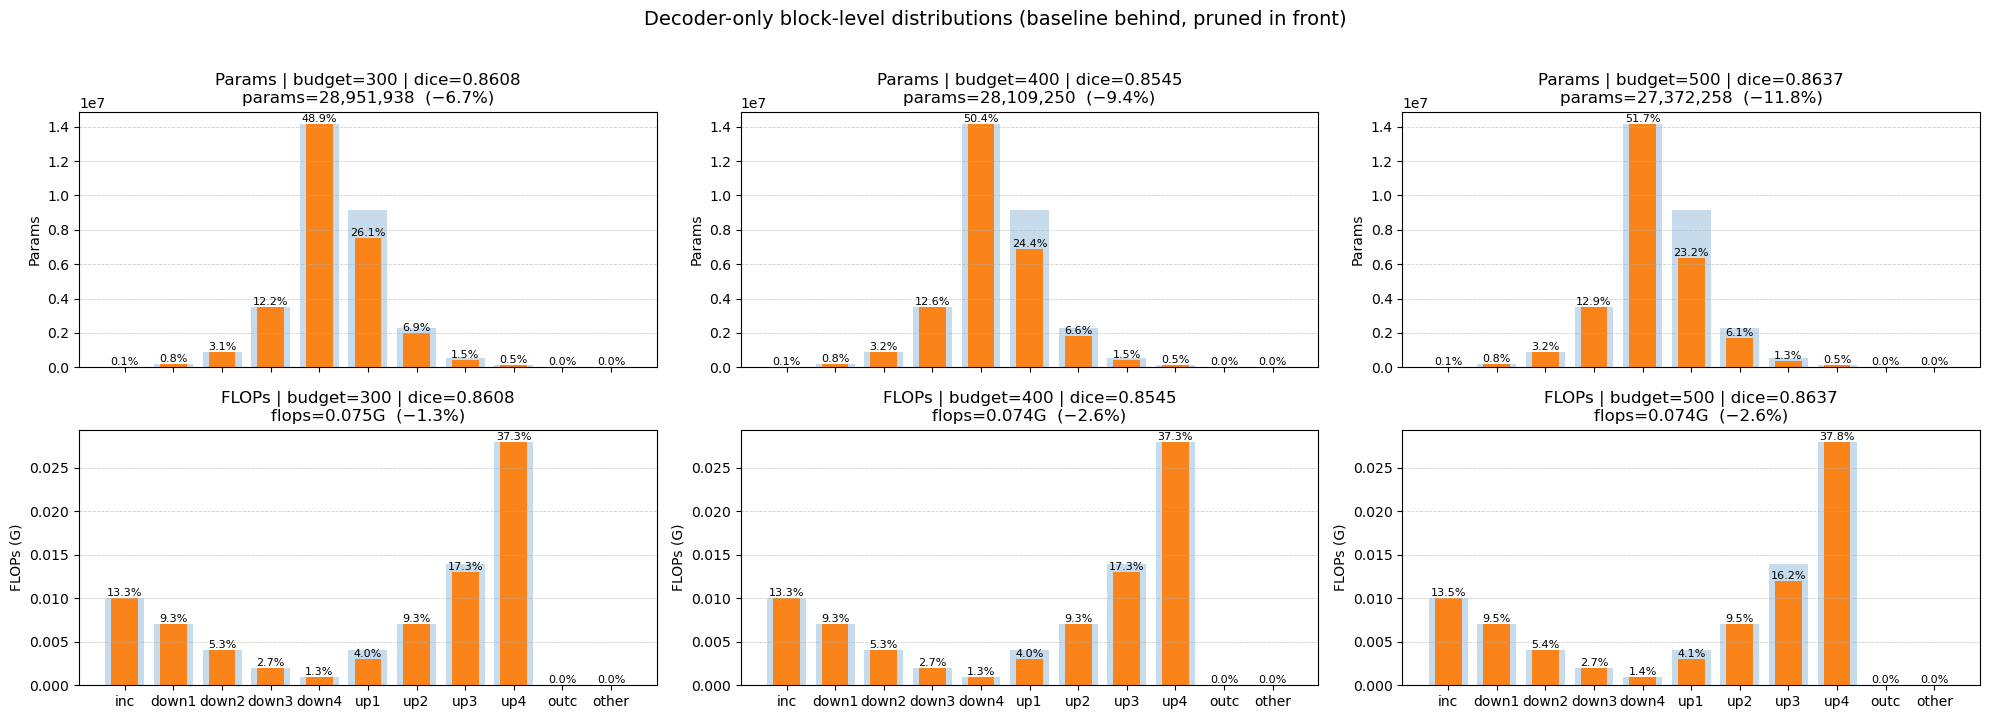

In [22]:
# Cell 13 (REPLACEMENT) — Decoder-only deep dive (BLOCK level) in ONE FIGURE:
# rows = [Params, FLOPs], cols = [budget 300, 400, 500]  -> 2 x 3 grid

import numpy as np
import matplotlib.pyplot as plt

def _bar_baseline_pruned(ax, labels, base_vals, pruned_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)

    # baseline behind
    ax.bar(x, base_vals, width=0.80, alpha=0.25)
    # pruned in front
    ax.bar(x, pruned_vals, width=0.55, alpha=0.95)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

    if share_of_total:
        tot = float(np.sum(pruned_vals)) if np.sum(pruned_vals) > 0 else 0.0
        if tot > 0:
            for i, v in enumerate(pruned_vals):
                pct = 100.0 * float(v) / tot
                ax.text(i, v, f"{pct:.1f}%", ha="center", va="bottom", fontsize=8)

def plot_blocks_grid(df_focus: pd.DataFrame):
    parts = PARTS_ALL.copy()
    dfp = df_focus.sort_values("budget").reset_index(drop=True)

    if len(dfp) != 3:
        print(f"[WARN] expected 3 rows (budgets 300/400/500), got {len(dfp)}. Plotting first 3.")
        dfp = dfp.head(3)

    fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False)

    for col, (_, row) in enumerate(dfp.iterrows()):
        b = int(row["budget"])

        # ---------- PARAMS (row 0) ----------
        base_p = _baseline_part_vals("params", parts)
        prun_p = _pruned_part_vals(row, "params", parts)

        title_p = (
            f"Params | budget={b} | dice={row['dice_pruned']:.4f}\n"
            f"params={int(row['params_pruned']):,}  (−{row['params_reduction_pct']:.1f}%)"
        )
        _bar_baseline_pruned(
            ax=axes[0, col],
            labels=parts,
            base_vals=base_p,
            pruned_vals=prun_p,
            title=title_p,
            ylabel="Params",
            share_of_total=True,
        )

        # ---------- FLOPs (row 1) ----------
        try:
            base_f = _baseline_part_vals("flops", parts)
            prun_f = _pruned_part_vals(row, "flops", parts)

            title_f = (
                f"FLOPs | budget={b} | dice={row['dice_pruned']:.4f}\n"
                f"flops={row['flops_g_pruned']:.3f}G  (−{row['flops_reduction_pct']:.1f}%)"
            )
            _bar_baseline_pruned(
                ax=axes[1, col],
                labels=parts,
                base_vals=base_f,
                pruned_vals=prun_f,
                title=title_f,
                ylabel="FLOPs (G)",
                share_of_total=True,
            )
        except Exception as e:
            axes[1, col].axis("off")
            axes[1, col].text(0.5, 0.5, f"FLOPs missing\n{e}", ha="center", va="center")

    # cosmetic: only show x tick labels on bottom row
    for j in range(3):
        axes[0, j].set_xticklabels([])
        axes[0, j].set_xlabel("")
        axes[1, j].tick_params(axis="x", labelrotation=0)

    fig.suptitle("Decoder-only block-level distributions (baseline behind, pruned in front)", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_blocks_grid(df_focus)


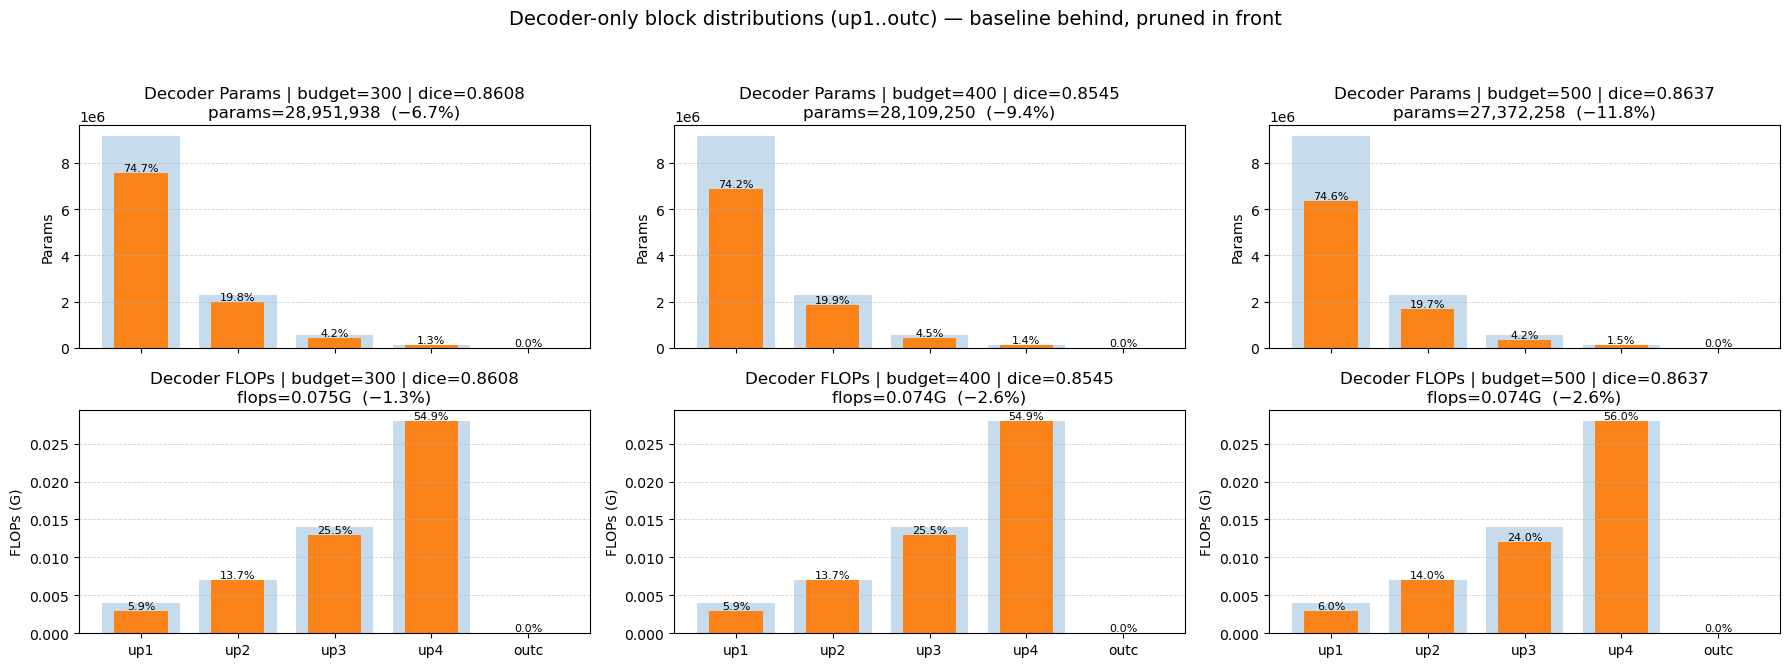

In [23]:
# Cell 14 — Decoder-only blocks ONLY (up1..outc) in ONE FIGURE:
# rows = [Params, FLOPs], cols = [budget 300, 400, 500]  -> 2 x 3 grid

import numpy as np
import matplotlib.pyplot as plt

DEC_BLOCKS = ["up1", "up2", "up3", "up4", "outc"]

def plot_decoder_blocks_grid(df_focus: pd.DataFrame):
    parts = [p for p in DEC_BLOCKS if p in PARTS_ALL]  # safety if "outc" etc. missing
    if len(parts) == 0:
        raise RuntimeError("None of the decoder parts (up1..outc) exist in PARTS_ALL / df_focus columns.")

    dfp = df_focus.sort_values("budget").reset_index(drop=True)
    if len(dfp) != 3:
        print(f"[WARN] expected 3 rows (budgets 300/400/500), got {len(dfp)}. Plotting first 3.")
        dfp = dfp.head(3)

    fig, axes = plt.subplots(2, 3, figsize=(18, 6.5), sharex=False)

    for col, (_, row) in enumerate(dfp.iterrows()):
        b = int(row["budget"])

        # PARAMS
        base_p = _baseline_part_vals("params", parts)
        prun_p = _pruned_part_vals(row, "params", parts)

        title_p = (
            f"Decoder Params | budget={b} | dice={row['dice_pruned']:.4f}\n"
            f"params={int(row['params_pruned']):,}  (−{row['params_reduction_pct']:.1f}%)"
        )
        _bar_baseline_pruned(
            ax=axes[0, col],
            labels=parts,
            base_vals=base_p,
            pruned_vals=prun_p,
            title=title_p,
            ylabel="Params",
            share_of_total=True,
        )

        # FLOPs
        try:
            base_f = _baseline_part_vals("flops", parts)
            prun_f = _pruned_part_vals(row, "flops", parts)

            title_f = (
                f"Decoder FLOPs | budget={b} | dice={row['dice_pruned']:.4f}\n"
                f"flops={row['flops_g_pruned']:.3f}G  (−{row['flops_reduction_pct']:.1f}%)"
            )
            _bar_baseline_pruned(
                ax=axes[1, col],
                labels=parts,
                base_vals=base_f,
                pruned_vals=prun_f,
                title=title_f,
                ylabel="FLOPs (G)",
                share_of_total=True,
            )
        except Exception as e:
            axes[1, col].axis("off")
            axes[1, col].text(0.5, 0.5, f"FLOPs missing\n{e}", ha="center", va="center")

    # cosmetic: only show x tick labels on bottom row
    for j in range(3):
        axes[0, j].set_xticklabels([])
        axes[0, j].set_xlabel("")
        axes[1, j].tick_params(axis="x", labelrotation=0)

    fig.suptitle("Decoder-only block distributions (up1..outc) — baseline behind, pruned in front", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_decoder_blocks_grid(df_focus)


In [24]:
# Cell 14 — (Optional) Numeric tables: group totals + deltas for 300/400/500

def _make_group_table(row: pd.Series) -> pd.DataFrame:
    # params
    prun_p_parts = {p: float(row[f"{p}_params_pruned"]) for p in PARTS_ALL}
    base_p_parts = {p: float(BASE[f"{p}_params_baseline"]) for p in PARTS_ALL if f"{p}_params_baseline" in df_baseline.columns}

    prun_p = _sum_by_groups(prun_p_parts)
    base_p = _sum_by_groups(base_p_parts)

    # flops (if present)
    have_flops = all(pd.notna(row.get(f"{p}_flops_g_pruned", np.nan)) for p in PARTS_ALL)

    rows = []
    for g in prun_p.keys():
        bp = base_p.get(g, np.nan)
        pp = prun_p.get(g, np.nan)
        rows.append({
            "group": g,
            "params_baseline": bp,
            "params_pruned": pp,
            "params_ratio": (pp / bp) if (bp and not np.isnan(bp)) else np.nan,
        })

    out = pd.DataFrame(rows)

    if have_flops:
        prun_f_parts = {p: float(row[f"{p}_flops_g_pruned"]) for p in PARTS_ALL}
        base_f_parts = {p: float(BASE[f"{p}_flops_g_baseline"]) for p in PARTS_ALL if f"{p}_flops_g_baseline" in df_baseline.columns}
        prun_f = _sum_by_groups(prun_f_parts)
        base_f = _sum_by_groups(base_f_parts)

        out["flops_g_baseline"] = out["group"].map(base_f)
        out["flops_g_pruned"] = out["group"].map(prun_f)
        out["flops_ratio"] = out["flops_g_pruned"] / out["flops_g_baseline"]

    out.insert(0, "budget", int(row["budget"]))
    out.insert(1, "dice_pruned", float(row["dice_pruned"]))
    return out

tables = []
for _, r in df_focus.sort_values("budget").iterrows():
    tables.append(_make_group_table(r))

df_groups_345 = pd.concat(tables, ignore_index=True)
display(df_groups_345)


,budget,dice_pruned,group,params_baseline,params_pruned,params_ratio,flops_g_baseline,flops_g_pruned,flops_ratio
0,300,0.860830,encoder,4687296.0,4687296.0,1.000000,0.023,0.023,1.000000
1,300,0.860830,bottleneck,14159872.0,14159872.0,1.000000,0.001,0.001,1.000000
2,300,0.860830,decoder,12190530.0,10104770.0,0.828903,0.053,0.051,0.962264
3,300,0.860830,other,0.0,0.0,NaN,0.000,0.000,NaN
4,400,0.854474,encoder,4687296.0,4687296.0,1.000000,0.023,0.023,1.000000
5,400,0.854474,bottleneck,14159872.0,14159872.0,1.000000,0.001,0.001,1.000000
6,400,0.854474,decoder,12190530.0,9262082.0,0.759777,0.053,0.051,0.962264
7,400,0.854474,other,0.0,0.0,NaN,0.000,0.000,NaN
8,500,0.863740,encoder,4687296.0,4687296.0,1.000000,0.023,0.023,1.000000
9,500,0.863740,bottleneck,14159872.0,14159872.0,1.000000,0.001,0.001,1.000000


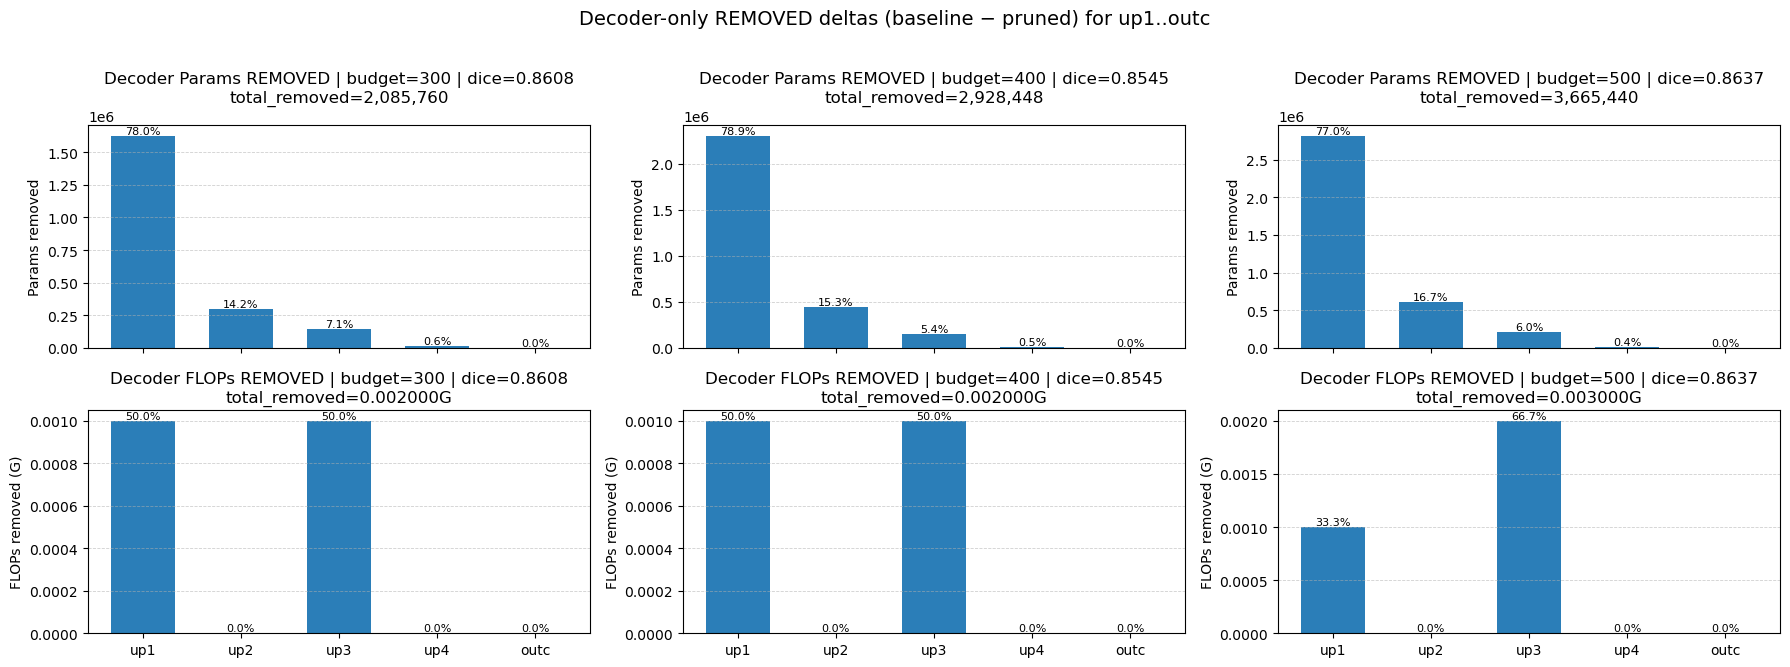

In [25]:
# Cell 15 — Decoder-only deltas (REMOVED) for decoder blocks only (up1..outc)
# rows = [Params removed, FLOPs removed], cols = [budget 300, 400, 500]  -> 2 x 3 grid
# "removed" = baseline - pruned (so bigger bar = more removed)

import numpy as np
import matplotlib.pyplot as plt

DEC_BLOCKS = ["up1", "up2", "up3", "up4", "outc"]

def _bar_removed(ax, labels, removed_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)

    ax.bar(x, removed_vals, width=0.65, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

    if share_of_total:
        tot = float(np.sum(removed_vals)) if np.sum(removed_vals) > 0 else 0.0
        if tot > 0:
            for i, v in enumerate(removed_vals):
                pct = 100.0 * float(v) / tot
                ax.text(i, v, f"{pct:.1f}%", ha="center", va="bottom", fontsize=8)

def plot_decoder_removed_grid(df_focus: pd.DataFrame):
    parts = [p for p in DEC_BLOCKS if p in PARTS_ALL]
    if len(parts) == 0:
        raise RuntimeError("None of the decoder parts (up1..outc) exist in PARTS_ALL / df_focus columns.")

    dfp = df_focus.sort_values("budget").reset_index(drop=True)
    if len(dfp) != 3:
        print(f"[WARN] expected 3 rows (budgets 300/400/500), got {len(dfp)}. Plotting first 3.")
        dfp = dfp.head(3)

    fig, axes = plt.subplots(2, 3, figsize=(18, 6.5), sharex=False)

    for col, (_, row) in enumerate(dfp.iterrows()):
        b = int(row["budget"])

        # -------- Params removed --------
        base_p = _baseline_part_vals("params", parts)
        prun_p = _pruned_part_vals(row, "params", parts)
        removed_p = np.maximum(base_p - prun_p, 0.0)

        title_p = (
            f"Decoder Params REMOVED | budget={b} | dice={row['dice_pruned']:.4f}\n"
            f"total_removed={int(removed_p.sum()):,}"
        )
        _bar_removed(
            ax=axes[0, col],
            labels=parts,
            removed_vals=removed_p,
            title=title_p,
            ylabel="Params removed",
            share_of_total=True,
        )

        # -------- FLOPs removed --------
        try:
            base_f = _baseline_part_vals("flops", parts)
            prun_f = _pruned_part_vals(row, "flops", parts)
            removed_f = np.maximum(base_f - prun_f, 0.0)

            title_f = (
                f"Decoder FLOPs REMOVED | budget={b} | dice={row['dice_pruned']:.4f}\n"
                f"total_removed={removed_f.sum():.6f}G"
            )
            _bar_removed(
                ax=axes[1, col],
                labels=parts,
                removed_vals=removed_f,
                title=title_f,
                ylabel="FLOPs removed (G)",
                share_of_total=True,
            )
        except Exception as e:
            axes[1, col].axis("off")
            axes[1, col].text(0.5, 0.5, f"FLOPs missing\n{e}", ha="center", va="center")

    # cosmetic: only show x tick labels on bottom row
    for j in range(3):
        axes[0, j].set_xticklabels([])
        axes[0, j].set_xlabel("")
        axes[1, j].tick_params(axis="x", labelrotation=0)

    fig.suptitle("Decoder-only REMOVED deltas (baseline − pruned) for up1..outc", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_decoder_removed_grid(df_focus)


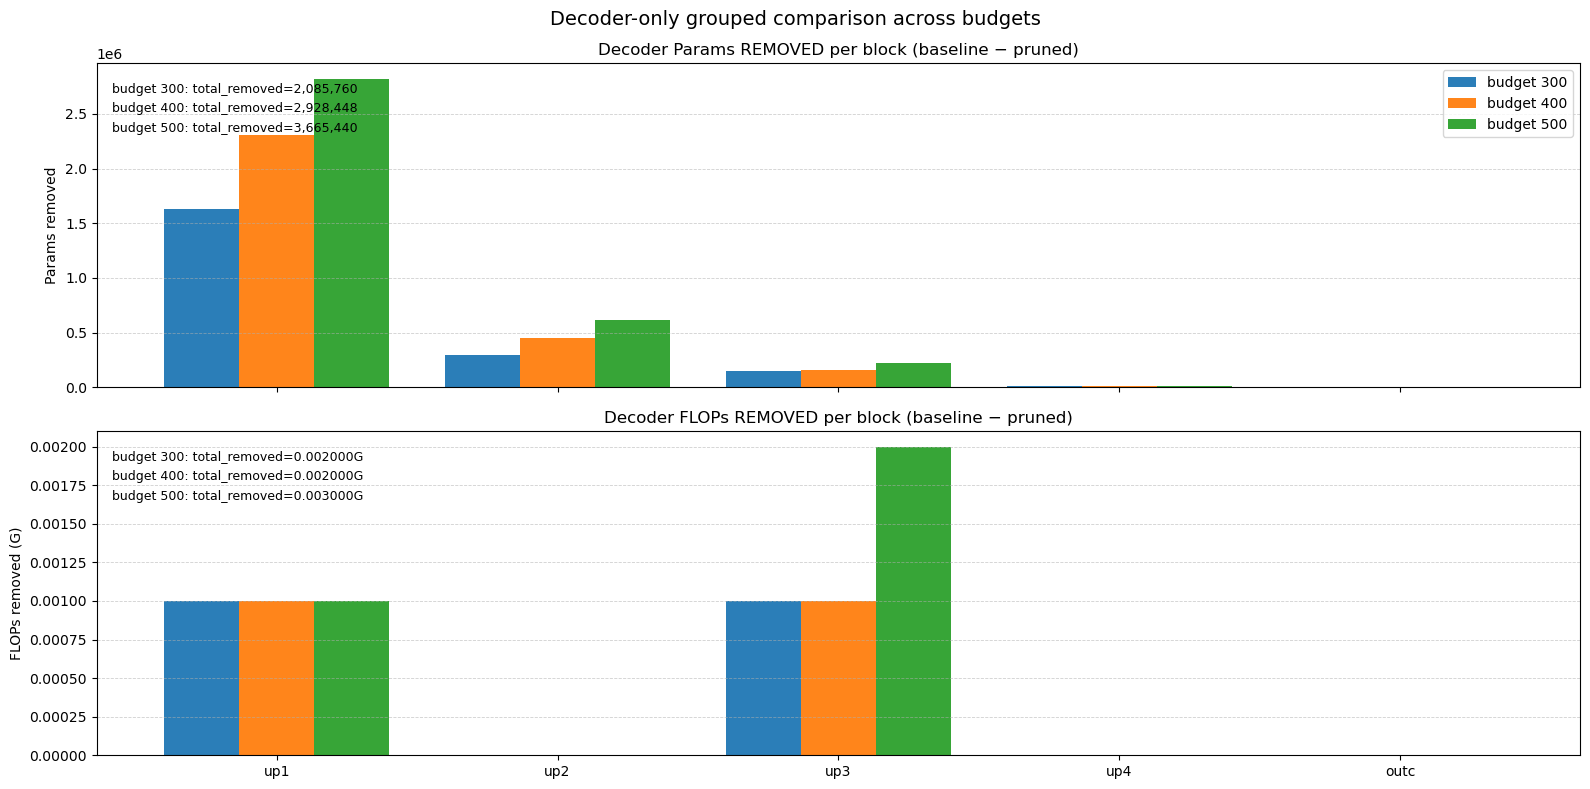

In [26]:
# Cell 16 — Grouped comparison across the 3 models (300/400/500) for decoder blocks only
# One figure, 2 rows:
#   Row 1: Params REMOVED (baseline - pruned)  [grouped bars per block]
#   Row 2: FLOPs  REMOVED (baseline - pruned)  [grouped bars per block]

import numpy as np
import matplotlib.pyplot as plt

DEC_BLOCKS = ["up1", "up2", "up3", "up4", "outc"]

def plot_decoder_removed_grouped(df_focus: pd.DataFrame):
    parts = [p for p in DEC_BLOCKS if p in PARTS_ALL]
    if len(parts) == 0:
        raise RuntimeError("None of the decoder parts (up1..outc) exist in PARTS_ALL / df_focus columns.")

    dfp = df_focus.sort_values("budget").reset_index(drop=True)
    budgets = dfp["budget"].astype(int).tolist()
    if len(budgets) < 2:
        raise RuntimeError("Need at least 2 models in df_focus for grouped comparison.")

    # matrices: (n_models, n_parts)
    P_removed = []
    F_removed = []
    for _, row in dfp.iterrows():
        base_p = _baseline_part_vals("params", parts)
        prun_p = _pruned_part_vals(row, "params", parts)
        P_removed.append(np.maximum(base_p - prun_p, 0.0))

        try:
            base_f = _baseline_part_vals("flops", parts)
            prun_f = _pruned_part_vals(row, "flops", parts)
            F_removed.append(np.maximum(base_f - prun_f, 0.0))
        except Exception:
            F_removed.append(None)

    P_removed = np.stack(P_removed, axis=0)  # (M, K)

    have_flops = all(x is not None for x in F_removed)
    if have_flops:
        F_removed = np.stack(F_removed, axis=0)  # (M, K)

    x = np.arange(len(parts), dtype=float)
    M = len(budgets)
    width = 0.8 / M

    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

    # ---------------- Params removed (grouped) ----------------
    for i, b in enumerate(budgets):
        axes[0].bar(x + (i - (M - 1) / 2) * width, P_removed[i], width=width, alpha=0.95, label=f"budget {b}")
    axes[0].set_title("Decoder Params REMOVED per block (baseline − pruned)")
    axes[0].set_ylabel("Params removed")
    axes[0].grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    axes[0].legend()

    # annotate totals per model
    totals_p = P_removed.sum(axis=1)
    ytop = float(P_removed.max()) if P_removed.size else 0.0
    for i, b in enumerate(budgets):
        axes[0].text(0.01, 0.92 - 0.06*i, f"budget {b}: total_removed={int(totals_p[i]):,}",
                     transform=axes[0].transAxes, ha="left", va="center", fontsize=9)

    # ---------------- FLOPs removed (grouped) ----------------
    if have_flops:
        for i, b in enumerate(budgets):
            axes[1].bar(x + (i - (M - 1) / 2) * width, F_removed[i], width=width, alpha=0.95, label=f"budget {b}")
        axes[1].set_title("Decoder FLOPs REMOVED per block (baseline − pruned)")
        axes[1].set_ylabel("FLOPs removed (G)")
        axes[1].grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)

        totals_f = F_removed.sum(axis=1)
        for i, b in enumerate(budgets):
            axes[1].text(0.01, 0.92 - 0.06*i, f"budget {b}: total_removed={totals_f[i]:.6f}G",
                         transform=axes[1].transAxes, ha="left", va="center", fontsize=9)
    else:
        axes[1].axis("off")
        axes[1].text(0.5, 0.5, "FLOPs per-block not available for all models", ha="center", va="center")

    axes[1].set_xticks(x)
    axes[1].set_xticklabels(parts, rotation=0)

    fig.suptitle("Decoder-only grouped comparison across budgets", y=0.98, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_decoder_removed_grouped(df_focus)


## at {1100, 1200, 1300} channels

,budget,model_name,dice_pruned,params_pruned,flops_g_pruned,log_path
0,1100,dec_only_d1100,0.838935,24082754,0.070,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,1200,dec_only_d1200,0.841153,23554658,0.069,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,1300,dec_only_d1300,0.833719,23158914,0.069,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


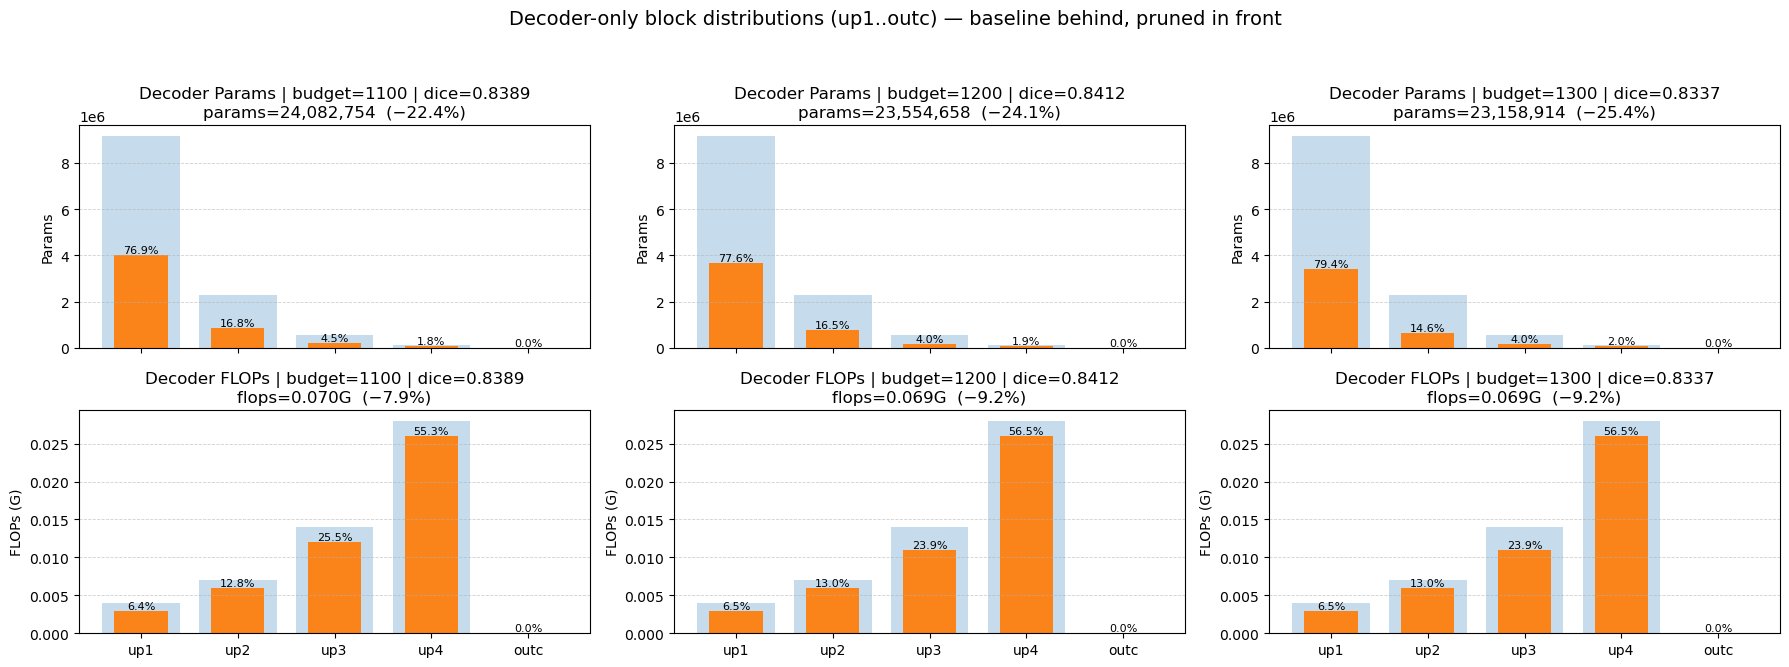

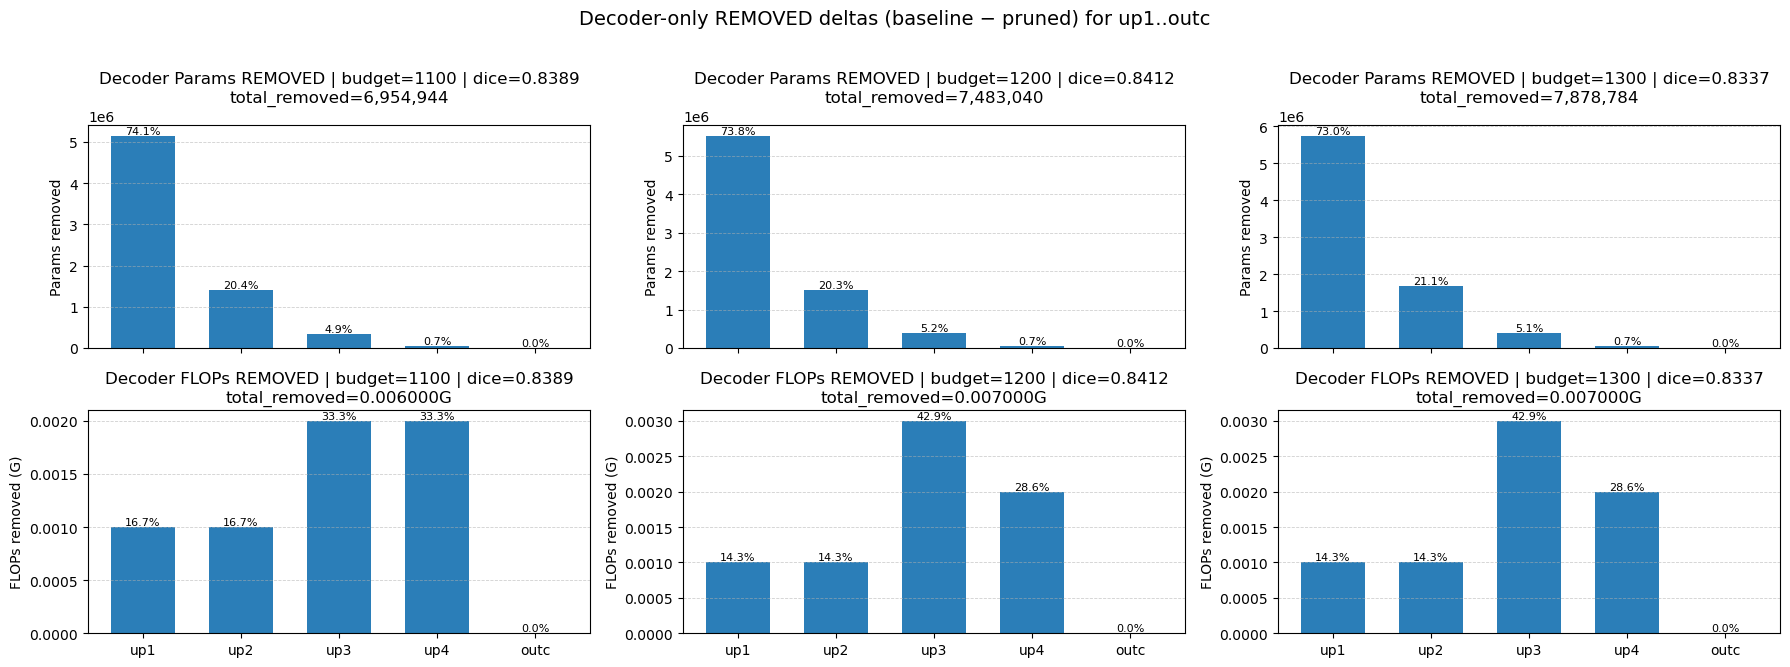

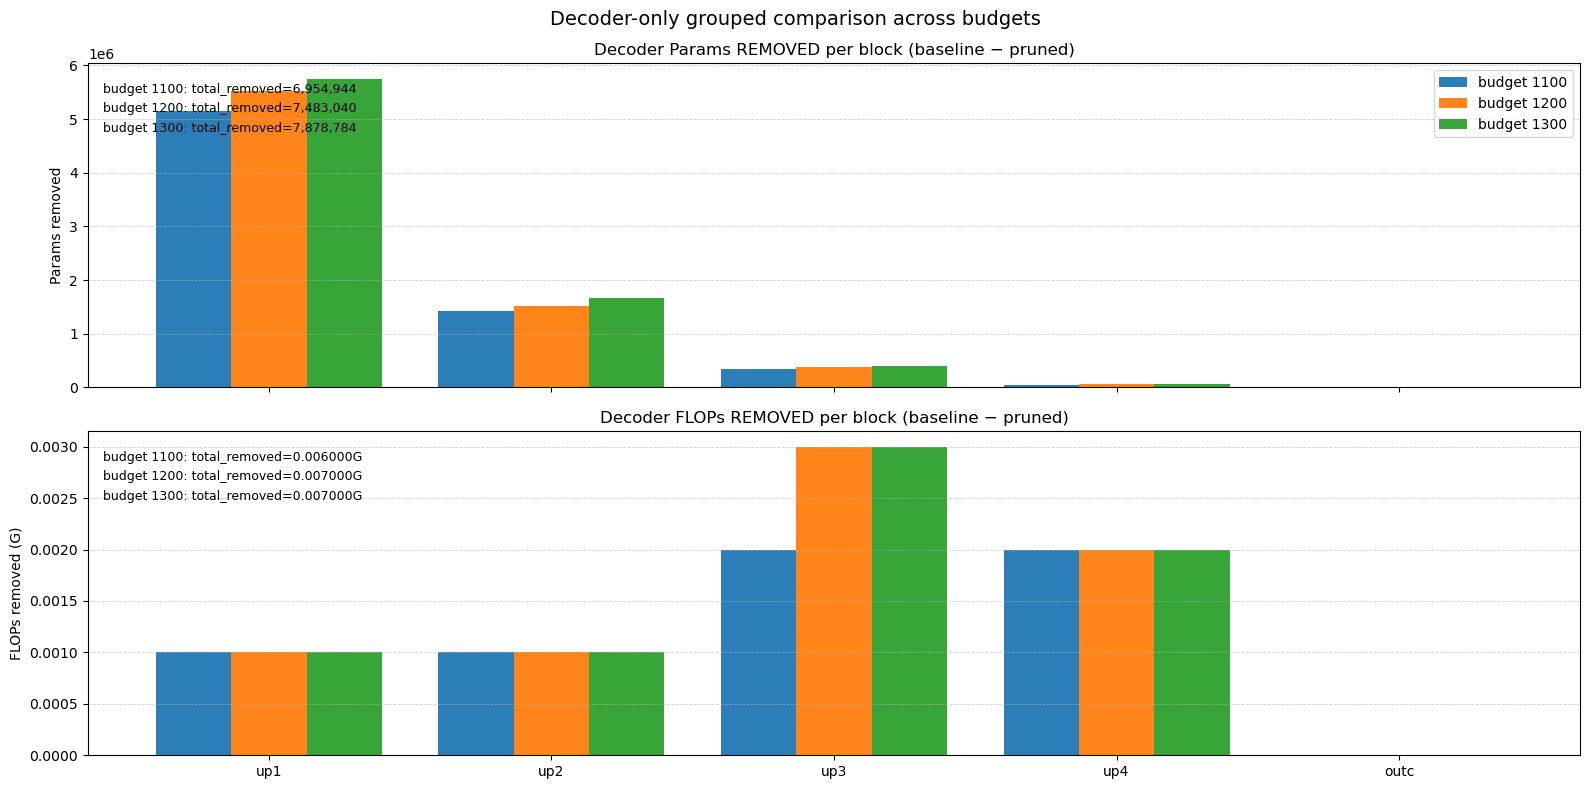

In [27]:
# Cell 17 — Repeat the whole analysis for decoder-only budgets 1100/1200/1300
# This cell:
#  1) builds df_focus_1100 from df_runs
#  2) runs the SAME plotting functions you already defined:
#       - plot_decoder_blocks_grid
#       - plot_decoder_removed_grid
#       - plot_decoder_removed_grouped
# and (optionally) the full-block grid if you want:
#       - plot_blocks_grid

TARGET_BUDGETS_2 = [1100, 1200, 1300]

# ---- select decoder-only rows ----
df_dec2 = df_runs[
    (df_runs["experiment_type"] == "dec_only") &
    (df_runs["requested_budget_channels"].isin(TARGET_BUDGETS_2))
].copy()

if df_dec2.empty:
    raise RuntimeError("No decoder-only runs found for budgets 1100/1200/1300 in df_runs.")

picked2 = []
for b in TARGET_BUDGETS_2:
    d = df_dec2[df_dec2["requested_budget_channels"] == b].dropna(subset=["dice_pruned"]).copy()
    if d.empty:
        raise RuntimeError(f"No decoder-only runs with dice_pruned for budget={b}.")
    # keep consistent with earlier rule: best for each budget (you can change 1200 to worst if needed)
    row = d.sort_values("dice_pruned", ascending=False).iloc[0]
    picked2.append(row)

df_focus_1100 = pd.DataFrame(picked2).reset_index(drop=True)
df_focus_1100["budget"] = df_focus_1100["requested_budget_channels"].astype(int)

display(df_focus_1100[["budget","model_name","dice_pruned","params_pruned","flops_g_pruned","log_path"]])

# ---- run the same plots ----
# Full blocks (all parts) grid (if you want the exact same set as before)
# plot_blocks_grid(df_focus_1100)

# Decoder-only blocks (up1..outc) grid
plot_decoder_blocks_grid(df_focus_1100)

# Decoder-only REMOVED deltas (up1..outc) grid
plot_decoder_removed_grid(df_focus_1100)

# Grouped comparison across the 3 budgets (up1..outc)
plot_decoder_removed_grouped(df_focus_1100)


,budget,dice_pruned,pruned_channels_path
0,300,0.860830,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,400,0.854474,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,500,0.863740,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


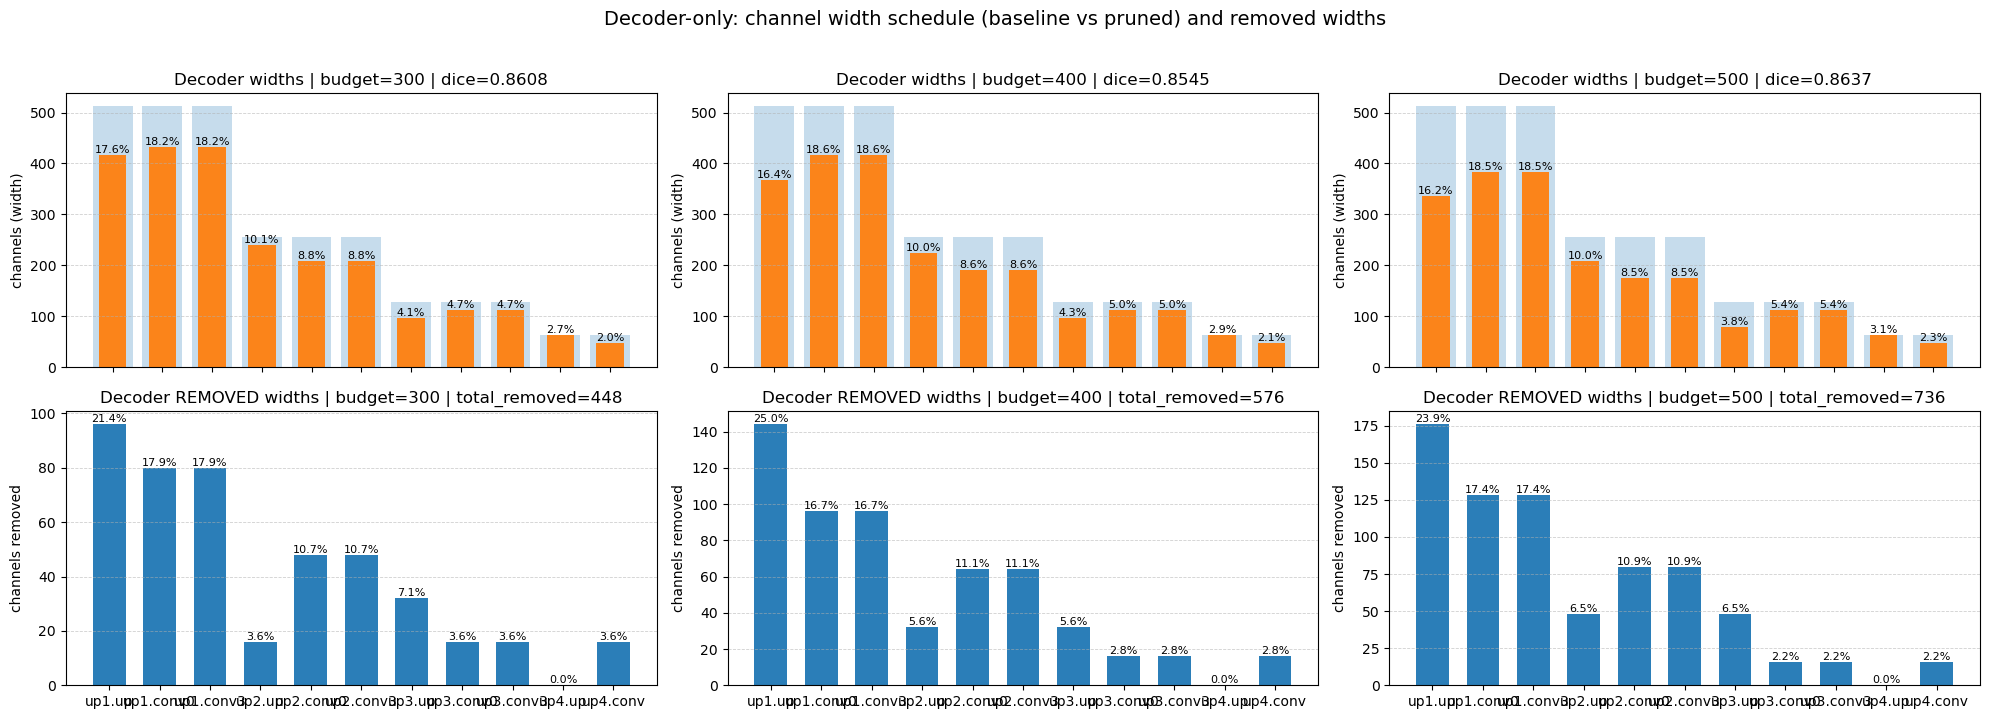

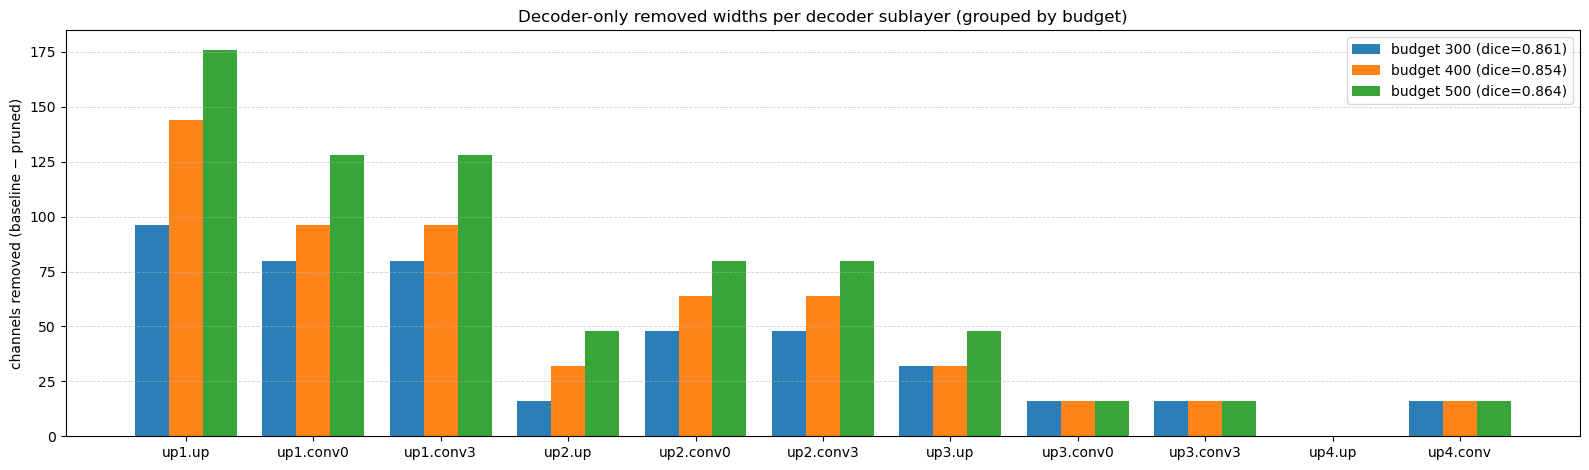

In [28]:
# Cell — FIX: Decoder-only analysis from pruned_channels.txt numeric width lists
# Produces:
#   df_dec_width_focus: per-focus run decoder widths + removed widths
#   2x3 plots: (row1 widths baseline vs pruned, row2 removed widths)
#   grouped comparison plot: removed widths across the 3 budgets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# Helpers: locate baseline channels file + read int lists
# -----------------------------
def _read_int_list(path: str):
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(str(p))
    vals = []
    for ln in p.read_text(encoding="utf-8", errors="ignore").splitlines():
        s = ln.strip()
        if not s:
            continue
        if s.lstrip("-").isdigit():
            vals.append(int(s))
    if len(vals) == 0:
        raise RuntimeError(f"Empty/invalid int list: {path}")
    return vals

def _find_upwards(start: Path, filename: str, max_up: int = 10) -> str:
    cur = start
    for _ in range(max_up):
        cand = cur / filename
        if cand.exists():
            return str(cand)
        if cur.parent == cur:
            break
        cur = cur.parent
    return ""

def locate_baseline_channels_txt(example_row: pd.Series) -> str:
    # priority: arg_channel_txt if your notebook keeps args as columns
    fname = None
    for key in ["arg_channel_txt", "channel_txt"]:
        if key in example_row and isinstance(example_row[key], str) and example_row[key]:
            fname = example_row[key]
            break
    if fname is None:
        fname = "model_channels.txt"

    lp = Path(example_row["log_path"])
    candidates = []

    # 1) try near log/run dir
    candidates.append(_find_upwards(lp.parent, fname, max_up=12))

    # 2) try common repo roots
    for root in [
        Path.cwd(),
        Path("/home/jovyan/work/src/Prune_U-Net"),
        Path("/home/jovyan/work/src/Prune_U-Net-master"),
        Path("/home/jovyan/work/src"),
    ]:
        cand = root / fname
        if cand.exists():
            candidates.append(str(cand))

    candidates = [c for c in candidates if c]
    if not candidates:
        raise RuntimeError(f"Could not locate baseline channels file '{fname}'.")
    return candidates[0]

def infer_dec_start(baseline: list[int], pruned: list[int]) -> int:
    n = min(len(baseline), len(pruned))
    for i in range(n):
        if baseline[i] != pruned[i]:
            return i
    return n

# -----------------------------
# Infer baseline channels + decoder segment structure
# -----------------------------
# We rely on df_focus having log_path + budget, and on df_focus having pruned_channels_path OR we locate it from log_path.
if "pruned_channels_path" not in df_focus.columns:
    # reuse locator you already used earlier (from the fix cell)
    def _locate_pruned_channels_txt_from_log(log_path: str) -> str:
        lp = Path(log_path)
        cand = lp.parent / "pruned_channels.txt"
        return str(cand) if cand.exists() else ""
    df_focus = df_focus.copy()
    df_focus["pruned_channels_path"] = df_focus["log_path"].apply(_locate_pruned_channels_txt_from_log)

if df_focus["pruned_channels_path"].isna().any() or (df_focus["pruned_channels_path"] == "").any():
    raise RuntimeError("Some df_focus rows have no pruned_channels_path. Ensure pruned_channels.txt exists per run.")

# baseline channels list (global)
base_path = locate_baseline_channels_txt(df_focus.iloc[0])
base_list = _read_int_list(base_path)

# infer decoder start index using one focus run (works for decoder-only)
pruned_list_0 = _read_int_list(df_focus.iloc[0]["pruned_channels_path"])
dec_start = infer_dec_start(base_list, pruned_list_0)

# decoder segment lengths / names
dec_len = len(base_list) - dec_start
# If this matches your common 11-element decoder signature, label nicely; otherwise generic labels.
if dec_len == 11:
    DEC_SIG = [
        "up1.up", "up1.conv0", "up1.conv3",
        "up2.up", "up2.conv0", "up2.conv3",
        "up3.up", "up3.conv0", "up3.conv3",
        "up4.up", "up4.conv",   # last entry often appears as single in your file
    ]
    dec_names = DEC_SIG
else:
    dec_names = [f"dec_{i}" for i in range(dec_len)]

# -----------------------------
# Build df for focus runs: widths + removed widths in decoder segment
# -----------------------------
rows = []
for _, r in df_focus.sort_values("budget").iterrows():
    pr_list = _read_int_list(r["pruned_channels_path"])

    n = min(len(base_list), len(pr_list))
    b_dec = np.array(base_list[dec_start:dec_start + dec_len], dtype=float)
    p_dec = np.array(pr_list[dec_start:dec_start + dec_len], dtype=float)
    removed = np.maximum(b_dec - p_dec, 0.0)

    row = {
        "budget": int(r["budget"]),
        "log_path": r["log_path"],
        "dice_pruned": float(r["dice_pruned"]),
        "baseline_channels_path": base_path,
        "pruned_channels_path": r["pruned_channels_path"],
        "dec_start": int(dec_start),
        "dec_len": int(dec_len),
    }
    for name, bv, pv, rv in zip(dec_names, b_dec, p_dec, removed):
        row[f"base_ch__{name}"] = bv
        row[f"pruned_ch__{name}"] = pv
        row[f"removed_ch__{name}"] = rv

    rows.append(row)

df_dec_width_focus = pd.DataFrame(rows)
display(df_dec_width_focus[["budget","dice_pruned","pruned_channels_path"]])

# -----------------------------
# Plotting (same comparison style): 2 rows x 3 cols
# -----------------------------
def _bar_baseline_pruned(ax, labels, base_vals, pruned_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)
    ax.bar(x, base_vals, width=0.80, alpha=0.25)   # baseline behind
    ax.bar(x, pruned_vals, width=0.55, alpha=0.95) # pruned front
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    if share_of_total:
        tot = float(np.sum(pruned_vals)) if np.sum(pruned_vals) > 0 else 0.0
        if tot > 0:
            for i, v in enumerate(pruned_vals):
                ax.text(i, v, f"{100*v/tot:.1f}%", ha="center", va="bottom", fontsize=8)

def _bar_removed(ax, labels, removed_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)
    ax.bar(x, removed_vals, width=0.65, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    if share_of_total:
        tot = float(np.sum(removed_vals)) if np.sum(removed_vals) > 0 else 0.0
        if tot > 0:
            for i, v in enumerate(removed_vals):
                ax.text(i, v, f"{100*v/tot:.1f}%", ha="center", va="bottom", fontsize=8)

# 2x3 figure
dfp = df_dec_width_focus.sort_values("budget").reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False)

labels = dec_names

for col in range(min(3, len(dfp))):
    row = dfp.iloc[col]
    base_vals = np.array([row[f"base_ch__{nm}"] for nm in labels], dtype=float)
    prun_vals = np.array([row[f"pruned_ch__{nm}"] for nm in labels], dtype=float)
    rem_vals  = np.array([row[f"removed_ch__{nm}"] for nm in labels], dtype=float)

    b = int(row["budget"])
    dice = float(row["dice_pruned"])

    _bar_baseline_pruned(
        axes[0, col], labels, base_vals, prun_vals,
        title=f"Decoder widths | budget={b} | dice={dice:.4f}",
        ylabel="channels (width)",
        share_of_total=True,
    )

    _bar_removed(
        axes[1, col], labels, rem_vals,
        title=f"Decoder REMOVED widths | budget={b} | total_removed={int(rem_vals.sum()):,}",
        ylabel="channels removed",
        share_of_total=True,
    )

# cosmetic
for j in range(3):
    axes[0, j].set_xticklabels([])
    axes[1, j].tick_params(axis="x", labelrotation=0)

fig.suptitle("Decoder-only: channel width schedule (baseline vs pruned) and removed widths", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# -----------------------------
# Grouped comparison: removed widths across the 3 budgets (one figure)
# -----------------------------
budgets = dfp["budget"].astype(int).tolist()
M = len(budgets)
x = np.arange(len(labels), dtype=float)
width = 0.8 / max(M, 1)

plt.figure(figsize=(16, 4.8))
for i in range(M):
    row = dfp.iloc[i]
    rem_vals = np.array([row[f"removed_ch__{nm}"] for nm in labels], dtype=float)
    plt.bar(x + (i - (M - 1) / 2) * width, rem_vals, width=width, alpha=0.95, label=f"budget {budgets[i]} (dice={row['dice_pruned']:.3f})")

plt.xticks(x, labels, rotation=0)
plt.ylabel("channels removed (baseline − pruned)")
plt.title("Decoder-only removed widths per decoder sublayer (grouped by budget)")
plt.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


,budget,dice_pruned,pruned_channels_path,log_path
0,1100,0.838935,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,1200,0.841153,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,1300,0.833719,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


,budget,dice_pruned,pruned_channels_path
0,1100,0.838935,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,1200,0.841153,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,1300,0.833719,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


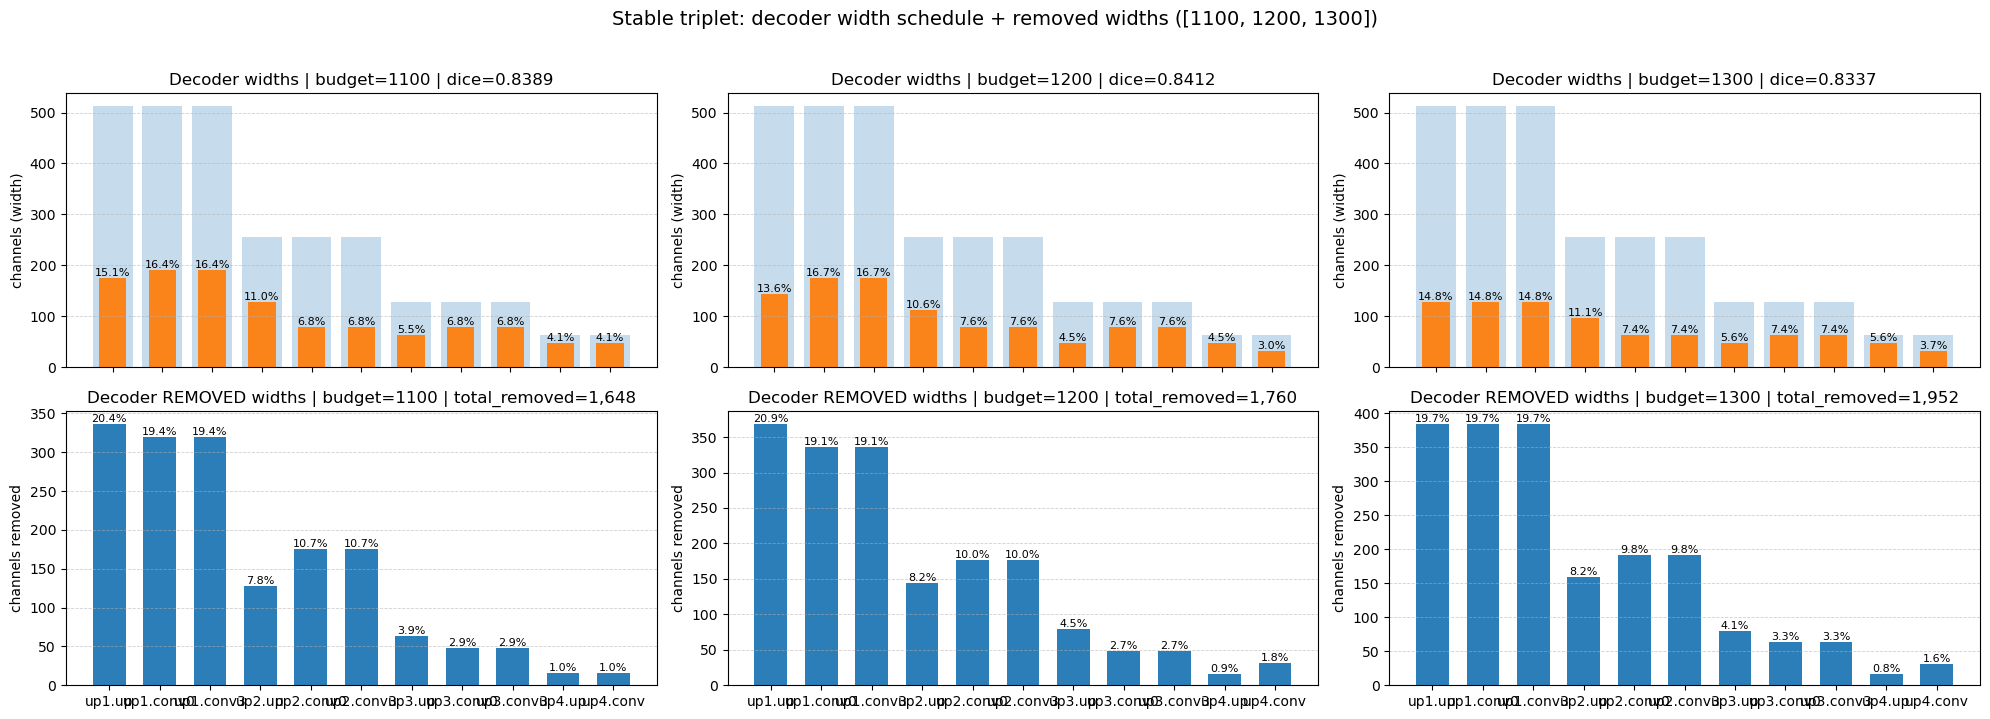

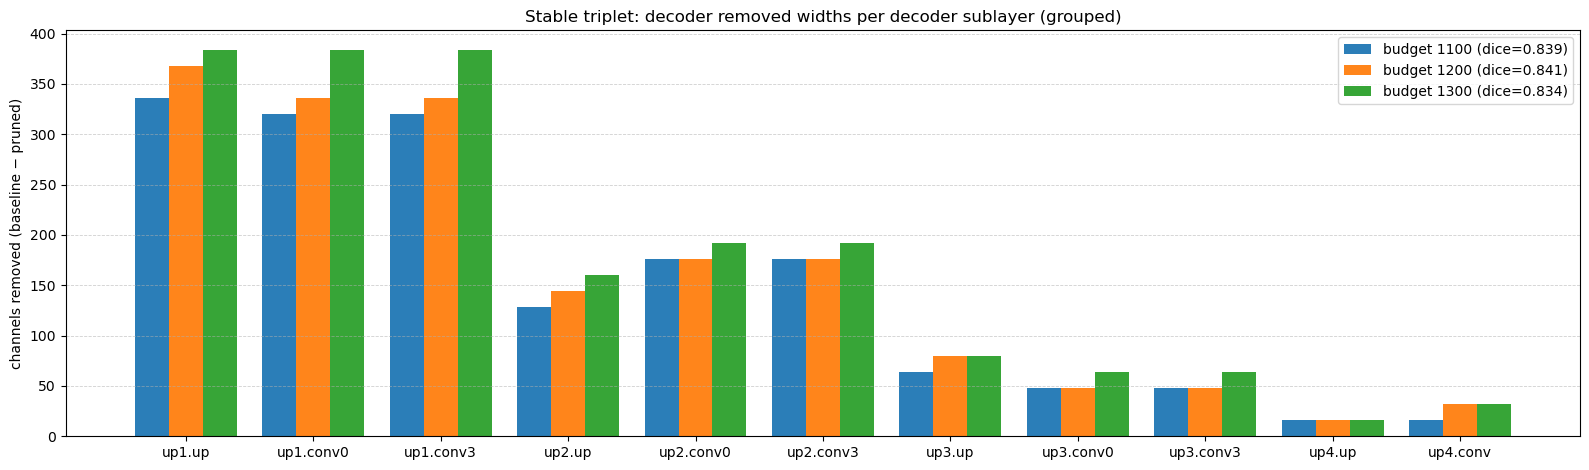

In [29]:
# Cell — SAME decoder-width schedule plots for a "stable" triplet (choose 3 budgets)
# Default here: 1100 / 1200 / 1300 (edit STABLE_BUDGETS if you want different ones)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

STABLE_BUDGETS = [1100, 1200, 1300]  # <-- change if needed

# ---- build df_focus_stable from df_runs (same rule: best dice per budget) ----
df_dec2 = df_runs[
    (df_runs["experiment_type"] == "dec_only") &
    (df_runs["requested_budget_channels"].isin(STABLE_BUDGETS))
].copy()

if df_dec2.empty:
    raise RuntimeError(f"No decoder-only runs found for budgets {STABLE_BUDGETS} in df_runs.")

picked = []
for b in STABLE_BUDGETS:
    d = df_dec2[df_dec2["requested_budget_channels"] == b].dropna(subset=["dice_pruned"]).copy()
    if d.empty:
        raise RuntimeError(f"No decoder-only runs with dice_pruned for budget={b}.")
    picked.append(d.sort_values("dice_pruned", ascending=False).iloc[0])

df_focus_stable = pd.DataFrame(picked).reset_index(drop=True)
df_focus_stable["budget"] = df_focus_stable["requested_budget_channels"].astype(int)

# ---- ensure pruned_channels_path exists ----
if "pruned_channels_path" not in df_focus_stable.columns:
    def _locate_pruned_channels_txt_from_log(log_path: str) -> str:
        lp = Path(log_path)
        cand = lp.parent / "pruned_channels.txt"
        return str(cand) if cand.exists() else ""
    df_focus_stable["pruned_channels_path"] = df_focus_stable["log_path"].apply(_locate_pruned_channels_txt_from_log)

if (df_focus_stable["pruned_channels_path"] == "").any():
    bad = df_focus_stable[df_focus_stable["pruned_channels_path"] == ""][["budget","log_path"]]
    raise RuntimeError(f"Missing pruned_channels.txt for some stable runs:\n{bad}")

display(df_focus_stable[["budget","dice_pruned","pruned_channels_path","log_path"]])

# ---- reuse baseline list + dec_start/dec_names from previous cell if available; otherwise recompute ----
def _read_int_list(path: str):
    p = Path(path)
    vals = []
    for ln in p.read_text(encoding="utf-8", errors="ignore").splitlines():
        s = ln.strip()
        if s and s.lstrip("-").isdigit():
            vals.append(int(s))
    if not vals:
        raise RuntimeError(f"Empty/invalid int list: {path}")
    return vals

def infer_dec_start(baseline: list[int], pruned: list[int]) -> int:
    n = min(len(baseline), len(pruned))
    for i in range(n):
        if baseline[i] != pruned[i]:
            return i
    return n

# baseline paths/arrays from previous cell, else re-locate
if "base_list" not in globals() or "base_path" not in globals():
    # fall back: assume baseline file name in args or default
    def _find_upwards(start: Path, filename: str, max_up: int = 10) -> str:
        cur = start
        for _ in range(max_up):
            cand = cur / filename
            if cand.exists():
                return str(cand)
            if cur.parent == cur:
                break
            cur = cur.parent
        return ""

    def locate_baseline_channels_txt(example_row: pd.Series) -> str:
        fname = None
        for key in ["arg_channel_txt", "channel_txt"]:
            if key in example_row and isinstance(example_row[key], str) and example_row[key]:
                fname = example_row[key]
                break
        if fname is None:
            fname = "model_channels.txt"
        lp = Path(example_row["log_path"])
        cand = _find_upwards(lp.parent, fname, max_up=12)
        if not cand:
            raise RuntimeError(f"Could not locate baseline channels file '{fname}'.")
        return cand

    base_path = locate_baseline_channels_txt(df_focus_stable.iloc[0])
    base_list = _read_int_list(base_path)

# infer dec_start/dec_names (use stable run 0, should match)
pruned0 = _read_int_list(df_focus_stable.iloc[0]["pruned_channels_path"])
dec_start = infer_dec_start(base_list, pruned0)
dec_len = len(base_list) - dec_start

if dec_len == 11:
    dec_names = [
        "up1.up", "up1.conv0", "up1.conv3",
        "up2.up", "up2.conv0", "up2.conv3",
        "up3.up", "up3.conv0", "up3.conv3",
        "up4.up", "up4.conv",
    ]
else:
    dec_names = [f"dec_{i}" for i in range(dec_len)]

# ---- build df_dec_width_stable ----
rows = []
for _, r in df_focus_stable.sort_values("budget").iterrows():
    pr_list = _read_int_list(r["pruned_channels_path"])
    b_dec = np.array(base_list[dec_start:dec_start + dec_len], dtype=float)
    p_dec = np.array(pr_list[dec_start:dec_start + dec_len], dtype=float)
    removed = np.maximum(b_dec - p_dec, 0.0)

    row = {
        "budget": int(r["budget"]),
        "log_path": r["log_path"],
        "dice_pruned": float(r["dice_pruned"]),
        "pruned_channels_path": r["pruned_channels_path"],
        "dec_start": int(dec_start),
        "dec_len": int(dec_len),
    }
    for name, bv, pv, rv in zip(dec_names, b_dec, p_dec, removed):
        row[f"base_ch__{name}"] = bv
        row[f"pruned_ch__{name}"] = pv
        row[f"removed_ch__{name}"] = rv
    rows.append(row)

df_dec_width_stable = pd.DataFrame(rows)
display(df_dec_width_stable[["budget","dice_pruned","pruned_channels_path"]])

# ---- plotting helpers (reuse if already defined) ----
def _bar_baseline_pruned(ax, labels, base_vals, pruned_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)
    ax.bar(x, base_vals, width=0.80, alpha=0.25)
    ax.bar(x, pruned_vals, width=0.55, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    if share_of_total:
        tot = float(np.sum(pruned_vals)) if np.sum(pruned_vals) > 0 else 0.0
        if tot > 0:
            for i, v in enumerate(pruned_vals):
                ax.text(i, v, f"{100*v/tot:.1f}%", ha="center", va="bottom", fontsize=8)

def _bar_removed(ax, labels, removed_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)
    ax.bar(x, removed_vals, width=0.65, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    if share_of_total:
        tot = float(np.sum(removed_vals)) if np.sum(removed_vals) > 0 else 0.0
        if tot > 0:
            for i, v in enumerate(removed_vals):
                ax.text(i, v, f"{100*v/tot:.1f}%", ha="center", va="bottom", fontsize=8)

# ---- 2x3 grid: widths + removed ----
dfp = df_dec_width_stable.sort_values("budget").reset_index(drop=True)
labels = dec_names

fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False)

for col in range(min(3, len(dfp))):
    row = dfp.iloc[col]
    base_vals = np.array([row[f"base_ch__{nm}"] for nm in labels], dtype=float)
    prun_vals = np.array([row[f"pruned_ch__{nm}"] for nm in labels], dtype=float)
    rem_vals  = np.array([row[f"removed_ch__{nm}"] for nm in labels], dtype=float)

    b = int(row["budget"])
    dice = float(row["dice_pruned"])

    _bar_baseline_pruned(
        axes[0, col], labels, base_vals, prun_vals,
        title=f"Decoder widths | budget={b} | dice={dice:.4f}",
        ylabel="channels (width)",
        share_of_total=True,
    )
    _bar_removed(
        axes[1, col], labels, rem_vals,
        title=f"Decoder REMOVED widths | budget={b} | total_removed={int(rem_vals.sum()):,}",
        ylabel="channels removed",
        share_of_total=True,
    )

for j in range(3):
    axes[0, j].set_xticklabels([])
    axes[1, j].tick_params(axis="x", labelrotation=0)

fig.suptitle(f"Stable triplet: decoder width schedule + removed widths ({STABLE_BUDGETS})", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# ---- grouped comparison: removed widths across the 3 stable budgets ----
budgets = dfp["budget"].astype(int).tolist()
M = len(budgets)
x = np.arange(len(labels), dtype=float)
width = 0.8 / max(M, 1)

plt.figure(figsize=(16, 4.8))
for i in range(M):
    row = dfp.iloc[i]
    rem_vals = np.array([row[f"removed_ch__{nm}"] for nm in labels], dtype=float)
    plt.bar(x + (i - (M - 1) / 2) * width, rem_vals, width=width, alpha=0.95,
            label=f"budget {budgets[i]} (dice={row['dice_pruned']:.3f})")

plt.xticks(x, labels, rotation=0)
plt.ylabel("channels removed (baseline − pruned)")
plt.title("Stable triplet: decoder removed widths per decoder sublayer (grouped)")
plt.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


#### FLOPs

Baseline channels txt: /home/jovyan/pruning-datavol-1/Prune_U-Net/analysis/../model_channels.txt


,budget,dice_pruned,pruned_channels_path
0,300,0.860830,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
1,400,0.854474,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...
2,500,0.863740,/home/jovyan/pruning-datavol-1/Prune_U-Net/ana...


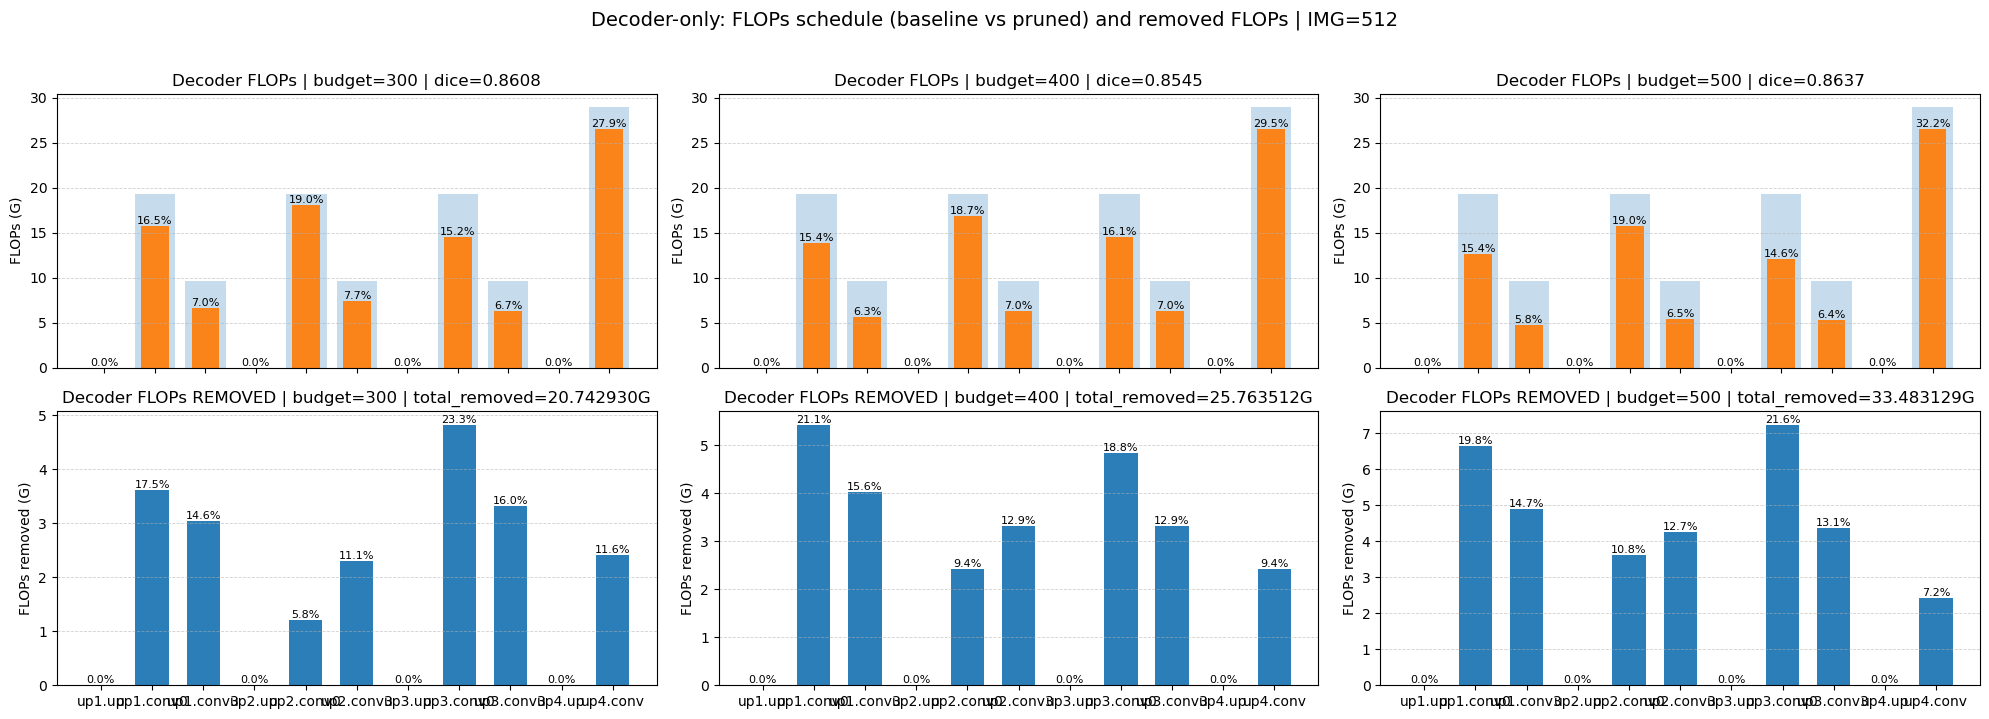

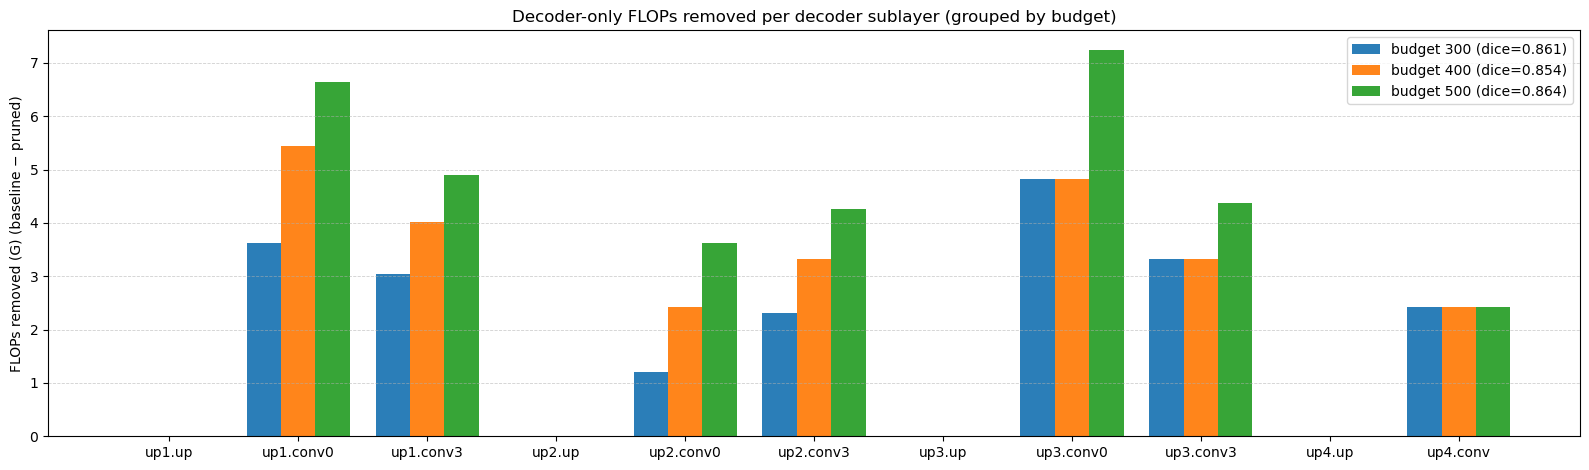

In [30]:
# Cell — Decoder-only FLOPs (G) from channel txt via Conv2d hook-formula, IMG=512
# Requires:
#   - df_focus with columns: budget, dice_pruned, log_path (and/or pruned_channels_path)
#   - build_model_for_checkpoint(channel_txt_path) that builds UNet from f_channels path
#   - locate_baseline_channels_txt + _read_int_list from your previous cell (optional but recommended)

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# CONFIG
# -----------------------------
IMG = 512
BATCH = 1
DEVICE = "cpu"          # FLOPs via hooks is fine on CPU
COUNT_MAC_AS_FLOPS = True  # matches your log convention (MACs)

# same decoder signature as your schedule plots
dec_names = [
    "up1.up", "up1.conv0", "up1.conv3",
    "up2.up", "up2.conv0", "up2.conv3",
    "up3.up", "up3.conv0", "up3.conv3",
    "up4.up", "up4.conv",
]

# -----------------------------
# Helpers
# -----------------------------
@torch.no_grad()
def conv_flops_from_hooks(model: nn.Module, input_shape=(1, 3, IMG, IMG), device=DEVICE):
    flops_g = {}

    def hook(name):
        def _h(m, inp, out):
            if not isinstance(out, torch.Tensor):
                return
            N, Cout, H, W = out.shape
            Cin = m.in_channels
            g = m.groups
            Kh, Kw = m.kernel_size
            macs = (N * H * W) * (Cout * (Cin / g) * Kh * Kw)
            fl = macs if COUNT_MAC_AS_FLOPS else (2.0 * macs)
            flops_g[name] = float(fl) / 1e9
        return _h

    model = model.to(device).eval()
    handles = []
    for n, m in model.named_modules():
        if isinstance(m, nn.Conv2d):
            handles.append(m.register_forward_hook(hook(n)))

    x = torch.zeros(*input_shape, device=device, dtype=torch.float32)
    _ = model(x)

    for h in handles:
        h.remove()

    return flops_g

def aggregate_decoder_sublayers(conv_flops_g: dict) -> dict:
    """
    Maps Conv2d module names -> your decoder labels.
    Assumes conv names include:
      up1.conv.double_conv.0 / .3
      ...
      up4.conv.double_conv.0 / .3
    """
    out = {k: 0.0 for k in dec_names}

    for name, g in conv_flops_g.items():
        if not name.startswith(("up1.", "up2.", "up3.", "up4.")):
            continue

        if ".conv.double_conv.0" in name:
            blk = name.split(".")[0]
            lbl = f"{blk}.conv0" if blk != "up4" else "up4.conv"
            out[lbl] += g

        elif ".conv.double_conv.3" in name:
            blk = name.split(".")[0]
            lbl = f"{blk}.conv3" if blk != "up4" else "up4.conv"
            out[lbl] += g

    return out

def _bar_baseline_pruned(ax, labels, base_vals, pruned_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)
    ax.bar(x, base_vals, width=0.80, alpha=0.25)
    ax.bar(x, pruned_vals, width=0.55, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    if share_of_total:
        tot = float(np.sum(pruned_vals))
        if tot > 0:
            for i, v in enumerate(pruned_vals):
                ax.text(i, v, f"{100*v/tot:.1f}%", ha="center", va="bottom", fontsize=8)

def _bar_removed(ax, labels, removed_vals, title, ylabel, share_of_total=True):
    x = np.arange(len(labels), dtype=float)
    ax.bar(x, removed_vals, width=0.65, alpha=0.95)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
    if share_of_total:
        tot = float(np.sum(removed_vals))
        if tot > 0:
            for i, v in enumerate(removed_vals):
                ax.text(i, v, f"{100*v/tot:.1f}%", ha="center", va="bottom", fontsize=8)

# -----------------------------
# Ensure pruned_channels_path exists
# -----------------------------
if "pruned_channels_path" not in df_focus.columns:
    def _locate_pruned_channels_txt_from_log(log_path: str) -> str:
        lp = Path(log_path)
        cand = lp.parent / "pruned_channels.txt"
        return str(cand) if cand.exists() else ""
    df_focus = df_focus.copy()
    df_focus["pruned_channels_path"] = df_focus["log_path"].apply(_locate_pruned_channels_txt_from_log)

if (df_focus["pruned_channels_path"].isna().any()) or (df_focus["pruned_channels_path"] == "").any():
    bad = df_focus[df_focus["pruned_channels_path"].isna() | (df_focus["pruned_channels_path"] == "")]
    raise RuntimeError(f"Missing pruned_channels.txt for some rows:\n{bad[['budget','log_path']]}")

# -----------------------------
# BASELINE channels file path (fix for your error)
# -----------------------------
# Use the same locator you used earlier in the widths cell:
base_path = locate_baseline_channels_txt(df_focus.iloc[0])   # <-- must exist from previous cell
print("Baseline channels txt:", base_path)

# -----------------------------
# Compute baseline FLOPs (decoder labels) once
# -----------------------------
base_model = build_model_for_checkpoint(base_path)
base_conv = conv_flops_from_hooks(base_model, input_shape=(BATCH, 3, IMG, IMG), device=DEVICE)
base_dec = aggregate_decoder_sublayers(base_conv)

# -----------------------------
# Compute per-run FLOPs (decoder labels)
# -----------------------------
rows = []
for _, r in df_focus.sort_values("budget").iterrows():
    pr_path = r["pruned_channels_path"]
    pr_model = build_model_for_checkpoint(pr_path)

    pr_conv = conv_flops_from_hooks(pr_model, input_shape=(BATCH, 3, IMG, IMG), device=DEVICE)
    pr_dec = aggregate_decoder_sublayers(pr_conv)

    row = {"budget": int(r["budget"]), "dice_pruned": float(r["dice_pruned"]), "pruned_channels_path": pr_path}
    for lbl in dec_names:
        bv = float(base_dec.get(lbl, 0.0))
        pv = float(pr_dec.get(lbl, 0.0))
        row[f"base_flops__{lbl}"] = bv
        row[f"pruned_flops__{lbl}"] = pv
        row[f"removed_flops__{lbl}"] = max(bv - pv, 0.0)
    rows.append(row)

df_dec_flops_focus = pd.DataFrame(rows)
display(df_dec_flops_focus[["budget", "dice_pruned", "pruned_channels_path"]])

# -----------------------------
# 2x3 plot
# -----------------------------
dfp = df_dec_flops_focus.sort_values("budget").reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False)

for col in range(min(3, len(dfp))):
    row = dfp.iloc[col]
    b = int(row["budget"])
    dice = float(row["dice_pruned"])

    base_vals = np.array([row[f"base_flops__{nm}"] for nm in dec_names], dtype=float)
    prun_vals = np.array([row[f"pruned_flops__{nm}"] for nm in dec_names], dtype=float)
    rem_vals  = np.array([row[f"removed_flops__{nm}"] for nm in dec_names], dtype=float)

    _bar_baseline_pruned(
        axes[0, col], dec_names, base_vals, prun_vals,
        title=f"Decoder FLOPs | budget={b} | dice={dice:.4f}",
        ylabel="FLOPs (G)",
        share_of_total=True,
    )
    _bar_removed(
        axes[1, col], dec_names, rem_vals,
        title=f"Decoder FLOPs REMOVED | budget={b} | total_removed={rem_vals.sum():.6f}G",
        ylabel="FLOPs removed (G)",
        share_of_total=True,
    )

for j in range(3):
    axes[0, j].set_xticklabels([])
    axes[1, j].tick_params(axis="x", labelrotation=0)

fig.suptitle(f"Decoder-only: FLOPs schedule (baseline vs pruned) and removed FLOPs | IMG={IMG}", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# -----------------------------
# Grouped comparison
# -----------------------------
budgets = dfp["budget"].astype(int).tolist()
M = len(budgets)
x = np.arange(len(dec_names), dtype=float)
width = 0.8 / max(M, 1)

plt.figure(figsize=(16, 4.8))
for i in range(M):
    row = dfp.iloc[i]
    rem_vals = np.array([row[f"removed_flops__{nm}"] for nm in dec_names], dtype=float)
    plt.bar(x + (i - (M - 1) / 2) * width, rem_vals, width=width, alpha=0.95,
            label=f"budget {budgets[i]} (dice={row['dice_pruned']:.3f})")

plt.xticks(x, dec_names, rotation=0)
plt.ylabel("FLOPs removed (G) (baseline − pruned)")
plt.title("Decoder-only FLOPs removed per decoder sublayer (grouped by budget)")
plt.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


In [31]:
# Cell — Decoder-only FLOPs (G) for the OTHER triplet (same pipeline), IMG=512
# Assumes:
#   - df_runs exists
#   - make_df_focus_dec_only(...) exists (from earlier)
#   - locate_baseline_channels_txt(...) exists
#   - build_model_for_checkpoint(path) exists
#   - conv_flops_from_hooks / aggregate_decoder_sublayers / _bar_* exist from previous FLOPs cell
# Produces: 2x3 + grouped comparison for the other triplet

# -----------------------------
# CONFIG: set the other triplet here
# -----------------------------
OTHER_BUDGETS = [1100, 1200, 1300]   # <-- change if needed
WORST_MIDDLE = None                 # or set to e.g. 1200 if you want "worst in the middle"

# decoder signature
dec_names = [
    "up1.up", "up1.conv0", "up1.conv3",
    "up2.up", "up2.conv0", "up2.conv3",
    "up3.up", "up3.conv0", "up3.conv3",
    "up4.up", "up4.conv",
]

# -----------------------------
# Build df_focus_other from df_runs
# -----------------------------
df_focus_other = make_df_focus_dec_only(df_runs, OTHER_BUDGETS, worst_middle_budget=WORST_MIDDLE)
display(df_focus_other[["budget","dice_pruned","log_path"]])

# ensure pruned_channels_path exists
if "pruned_channels_path" not in df_focus_other.columns:
    from pathlib import Path
    def _locate_pruned_channels_txt_from_log(log_path: str) -> str:
        lp = Path(log_path)
        cand = lp.parent / "pruned_channels.txt"
        return str(cand) if cand.exists() else ""
    df_focus_other = df_focus_other.copy()
    df_focus_other["pruned_channels_path"] = df_focus_other["log_path"].apply(_locate_pruned_channels_txt_from_log)

bad = df_focus_other[df_focus_other["pruned_channels_path"].isna() | (df_focus_other["pruned_channels_path"] == "")]
if len(bad) > 0:
    raise RuntimeError(f"Missing pruned_channels.txt for some rows:\n{bad[['budget','log_path']]}")

# -----------------------------
# Baseline (same baseline across runs)
# -----------------------------
base_path = locate_baseline_channels_txt(df_focus_other.iloc[0])
print("Baseline channels txt:", base_path)

base_model = build_model_for_checkpoint(base_path)
base_conv  = conv_flops_from_hooks(base_model, input_shape=(BATCH, 3, IMG, IMG), device=DEVICE)
base_dec   = aggregate_decoder_sublayers(base_conv)

# -----------------------------
# Compute per-run FLOPs (decoder labels)
# -----------------------------
rows = []
for _, r in df_focus_other.sort_values("budget").iterrows():
    pr_path = r["pruned_channels_path"]
    pr_model = build_model_for_checkpoint(pr_path)

    pr_conv = conv_flops_from_hooks(pr_model, input_shape=(BATCH, 3, IMG, IMG), device=DEVICE)
    pr_dec  = aggregate_decoder_sublayers(pr_conv)

    row = {"budget": int(r["budget"]), "dice_pruned": float(r["dice_pruned"]), "pruned_channels_path": pr_path}
    for lbl in dec_names:
        bv = float(base_dec.get(lbl, 0.0))
        pv = float(pr_dec.get(lbl, 0.0))
        row[f"base_flops__{lbl}"] = bv
        row[f"pruned_flops__{lbl}"] = pv
        row[f"removed_flops__{lbl}"] = max(bv - pv, 0.0)
    rows.append(row)

df_dec_flops_focus_other = pd.DataFrame(rows)
display(df_dec_flops_focus_other[["budget","dice_pruned","pruned_channels_path"]])

# -----------------------------
# 2x3 plot
# -----------------------------
dfp = df_dec_flops_focus_other.sort_values("budget").reset_index(drop=True)
fig, axes = plt.subplots(2, 3, figsize=(20, 7), sharex=False)

for col in range(min(3, len(dfp))):
    row = dfp.iloc[col]
    b = int(row["budget"])
    dice = float(row["dice_pruned"])

    base_vals = np.array([row[f"base_flops__{nm}"] for nm in dec_names], dtype=float)
    prun_vals = np.array([row[f"pruned_flops__{nm}"] for nm in dec_names], dtype=float)
    rem_vals  = np.array([row[f"removed_flops__{nm}"] for nm in dec_names], dtype=float)

    _bar_baseline_pruned(
        axes[0, col], dec_names, base_vals, prun_vals,
        title=f"Decoder FLOPs | budget={b} | dice={dice:.4f}",
        ylabel="FLOPs (G)",
        share_of_total=True,
    )
    _bar_removed(
        axes[1, col], dec_names, rem_vals,
        title=f"Decoder FLOPs REMOVED | budget={b} | total_removed={rem_vals.sum():.6f}G",
        ylabel="FLOPs removed (G)",
        share_of_total=True,
    )

for j in range(3):
    axes[0, j].set_xticklabels([])
    axes[1, j].tick_params(axis="x", labelrotation=0)

fig.suptitle(f"Decoder-only: FLOPs schedule (baseline vs pruned) and removed FLOPs | IMG={IMG}", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

# -----------------------------
# Grouped comparison
# -----------------------------
budgets = dfp["budget"].astype(int).tolist()
M = len(budgets)
x = np.arange(len(dec_names), dtype=float)
width = 0.8 / max(M, 1)

plt.figure(figsize=(16, 4.8))
for i in range(M):
    row = dfp.iloc[i]
    rem_vals = np.array([row[f"removed_flops__{nm}"] for nm in dec_names], dtype=float)
    plt.bar(x + (i - (M - 1) / 2) * width, rem_vals, width=width, alpha=0.95,
            label=f"budget {budgets[i]} (dice={row['dice_pruned']:.3f})")

plt.xticks(x, dec_names, rotation=0)
plt.ylabel("FLOPs removed (G) (baseline − pruned)")
plt.title("Decoder-only FLOPs removed per decoder sublayer (grouped by budget)")
plt.grid(True, axis="y", linestyle="--", linewidth=0.6, alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


NameError: name 'make_df_focus_dec_only' is not defined